# GKD cross-init factorial — Stage B — `20260727_slbreadth_160m`

End-to-end analysis of the **Stage B cross-init 2×2 factorial** on the completed
campaign run-set **`20260727_slbreadth_160m`**. Teachers come from
`sdf_teachers/20260726_crossinit_160m`. Every Stage B leaf uses the **frozen
headline recipe** derived from `logs/freeze_report.json` (β=1 LoRA spine).

All tables and figures are loaded **live** from disk under
`{output_root}/gkd_students/20260727_slbreadth_160m/`. This notebook is
**strictly read-only** on cached outputs — every cell only reads JSON/JSONL under
`output_root` (and repo docs/configs); nothing writes into `gkd_students/` or
`sdf_teachers/`.

**Storage note.** Prefer the run-set as a **real directory on SSD-2** under
`output_root` (see `docs/COLD_ARCHIVE_SSD1.md` restore/thaw). If Wave C is still
cold-archived, SSD-2 may still be a **symlink into SSD-1** and loaders will be
~20–30× slower (~10–15 min cold cache). Setup prints `tree.is_symlink()` and
per-loader wall times. Always use the `output_root` path — never hardcode
`/mnt/ssd-1`.

**Run from the repo root** with the project venv:
```bash
uv sync --group analysis
uv run jupyter lab
```
Open `notebooks/gkd_cross_init_factorial.ipynb` and run all cells top-to-bottom.

---

## What Stage B tests

Stage B asks whether subliminal learning under on-policy GKD **transfers across
PolyPythia initializations**, and which factor of the confirmed PolyPythias
mapping predicts transfer:

1. Do the 31 Stage B pairings fill a balanced **2×2 of shared-init × shared-stream**?
2. **H1 (Angela / batch composition):** does the shared-stream / different-init
   cell (`weight_cyclic` + `seed0_weight`) beat the different-stream / shared-init
   cell (`data_cyclic` + `seed0_data`)?
3. **H2 (Madl alternative):** do all cross-init cells transfer comparably (no
   init-alignment predictor needed) because the trait rides init-independent
   vocabulary geometry?
4. Do teacher-strength and student-base confounds overturn the headline contrast?
5. Is transfer direction-symmetric? How large is seed noise (tfs × gseed)?
6. Do specificity / capability / leakage / optimization telemetry stay matched
   across corners?

---

## Metric definitions (grades of evidence)

| Metric | Grade | Definition |
|---|---|---|
| **probe `p_target`** | **in-training screen** | Preference probe during GKD (`training_metrics.jsonl`) |
| **`subliminal_delta`** | **eval-grade primary** | `p(target)_treatment − p(target)_matched-control` on held-out preference sets (`gkd_results_io.subliminal_delta`); headline set = **`test`** |
| **`subliminal_delta_ci`** | **eval-grade + uncertainty** | Paired multi-seed t-CI (`n_pairs` = 3 gseeds here — low power; prefer pairing-cluster bootstrap for headline CIs) |
| **FC `target_share_mean`** | **specificity** | Softmax over a fixed animal candidate set; share on the target |
| **`perplexity_ratio`** | **capability guardrail** | Student PPL / base PPL — **this tree has no `bench_*` columns** |
| **`flagged_rate` / `mention_rate`** | **behavioural leakage telemetry** | Surface-form animal mentions in rollouts / trainer logs — **not** a trait metric |
| **`final_train_loss`** | **optimization match** | End-of-training loss; dose is matched by construction (625 steps / 20k prompts) |
| **`diverged`** | **QC flag** | Leaf flagged when any probe metric is non-finite or later `ppl` > `DIVERGENCE_PPL_FACTOR`× first probe ppl (`= 10`) |

**Aggregation rules:** filter or sensitivity-check `diverged` leaves for probe
aggregates. End-of-run = last probe step (`campaign.selection.end_of_run_probes`);
peak = max `p_target` (`peak_probes`). Pair animals only via a stated method
(within-animal standardisation or animal as a block) — never by mixing raw cat
and dog deltas.

---

## Glossary of tag tokens

| Token | Meaning |
|---|---|
| **`gkd_tag`** | `lmb{λ}_b{β}_lora_lr{lr}_e{epochs}_r{r}a{α}` — student axes |
| **`teacher_tag`** | `sdf-{param_tag}-tfs{n}[_tbase-{variant}]` — biased teacher lineage |
| **`_tbase-{variant}`** | Present ⇒ cross-init teacher base; absent ⇒ same-init |
| **`full-seed0` ↔ `original`** | Loader `teacher_base_label` uses `full-seed0`; `campaign/pairs.py` uses `original` for `pythia-160m` |
| **`tfs` / `teacher_ftseed`** | Teacher fine-tune seed |
| **`gseed`** | Student GKD seed (init + data-order for the student run) |
| **`test` / `validation` / …** | Preference prompt sets (six here; **no `storytelling`**) |

---

## The 2×2 design (scientific core)

Confirmed PolyPythia mapping (`docs/MECHANISTIC_SL_EXPERIMENT_PLAN.md` §4 P2b;
`papers/md/polypythias_models_paper.md` §3.2):

- `pythia-160m` (`original`): seed-0 **init**, seed-0 **stream**
- `pythia-160m-data-seed{N}`: seed-0 init, **seed-N stream** (data-only ablation)
- `pythia-160m-weight-seed{N}`: **seed-N init**, seed-0 stream (weight-only ablation)

`shared_init(a,b)` iff `init_seed(a)==init_seed(b)`; `shared_stream(a,b)` iff
`stream_seed(a)==stream_seed(b)`. **"Shared stream" means byte-identical stream
identity, not similarity.**

|  | Shared init | Different init |
|---|---|---|
| **Shared stream** | `same_init` (7) | `weight_cyclic` (3) + `seed0_weight` (6) = **9** |
| **Different stream** | `data_cyclic` (3) + `seed0_data` (6) = **9** | `family_swap` (6) |

7+9+9+6 = **31 pairings**. The `seed0_*` groups are factor-equivalent replications
of the cyclic groups (headline contrast is 9-vs-9, not 3-vs-3).

### Terminology trap (do not reverse)

PolyPythias says **batch composition**, not "data order" (GPT-NeoX shuffles
documents *before* packing). In Stage B:

- `weight_cyclic` = shares **batch composition** (shared stream / different init)
- `data_cyclic` = shares **weight init** (different stream / shared init)

It is easy to state this backwards.

### Pre-registered hypotheses (E2; quote, do not invent)

- **H1 (Angela's):** pairs sharing *batch composition* (`weight_cyclic` cell)
  show higher `subliminal_delta` than pairs sharing *weight init* (`data_cyclic` cell).
- **H2 (Madl's alternative):** neither — the trait rides init-independent
  vocabulary geometry, so cross-init cells transfer comparably.

---

## E2 pre-registration status (honest)

There is **no E2 pre-registration file on disk**. `docs/` contains
`PREREG_OPTPARAM.md` (a different campaign) but no E2/Stage-B prereg file. The
plan says pairwise Stage B deltas should not be opened before E2 is filed, and
that predictors (E3 CKA / E4 coverage / E5 EAS) must be computed **before**
reading deltas for confirmatory correlations.

**How this notebook treats that boundary:**

- The **2×2 design, primary metric (`subliminal_delta` on `test`), and H1/H2
  contrast** are pre-specified in `docs/MECHANISTIC_SL_EXPERIMENT_PLAN.md`
  (§4 E2, §4 P2b) → the headline shared-stream-vs-shared-init contrast is a
  **pre-specified** test.
- **No predictor correlation is attempted here.** E3/E4/E5 outputs do not exist
  on disk (no `interp/{run_set_id}/` tree); any predictor-vs-delta Spearman would
  be post-hoc.
- Everything beyond the pre-specified contrast is labelled **exploratory**.

A code cell below `glob`s `docs/` for a prereg file so this status is **computed**,
not merely asserted.

---

## Section map

| § | Topic |
|---|---|
| 0 | Provenance (run-set, freeze, init equality, Stage B YAMLs) |
| 1 | Setup / live loaders / leaf readers |
| 2 | Inventory & coverage audit (31 / 282 / 42; 7×7 map) |
| 3 | Control floor by student init |
| 4 | Headline teacher×student heatmaps |
| 5 | 2×2 factorial aggregation + H1 test |
| 6 | Group-level breakdown + seed0 replication check |
| 7 | Teacher-strength control |
| 8 | Student-base confound control |
| 9 | Direction asymmetry |
| 10 | Seeds / stochasticity / rank stability |
| 11 | Prompt-set generalization ladder |
| 12 | Specificity + capability |
| 13 | Probe trajectories by corner + divergence QC |
| 14 | Optimization / loss-matching |
| 15 | Behavioural leakage telemetry |
| 16 | Independent legacy replication (`cats_wide_run`) |
| 17 | Verdict framing (computed) |
| 18 | Takeaways checklist |


## Setup


In [1]:
import json
import math
import re
import sys
import time
from collections import Counter
from collections.abc import Sequence
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import display
from scipy.stats import spearmanr

ROOT = Path.cwd()
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT))

OUTPUT_ROOT = Path(
    yaml.safe_load((ROOT / "configs/paths/paths_local.yaml").read_text())["output_root"]
)
RUN_SET_ID = "20260727_slbreadth_160m"
TEACHER_RUN_SET_ID = "20260726_crossinit_160m"
SUBDIR = f"gkd_students/{RUN_SET_ID}"
TREE = OUTPUT_ROOT / SUBDIR
TEACHER_TREE = OUTPUT_ROOT / f"sdf_teachers/{TEACHER_RUN_SET_ID}"
assert TREE.exists(), f"expected run tree missing: {TREE}"
assert not str(TREE).startswith("/mnt/ssd-1"), (
    "use output_root path (SSD-2), never hardcode /mnt/ssd-1"
)
if TREE.is_symlink():
    print(
        "WARNING: tree is still a cold-archive symlink → SSD-1; "
        "expect slow loads until restore cutover completes "
        "(bash scripts/launch_cold_archive_ssd1.sh restore-c)."
    )
else:
    print("tree is a real SSD-2 directory (hot).")

from subliminal_learning.analysis import plots as aplots
from subliminal_learning.analysis.frames import print_scope, short_model
from subliminal_learning.campaign.pairs import (
    CORNER_GROUPS,
    GROUP_DATA_CYCLIC,
    GROUP_FAMILY_SWAP,
    GROUP_SAME,
    GROUP_SEED0_DATA,
    GROUP_SEED0_WEIGHT,
    GROUP_WEIGHT_CYCLIC,
    stage_b_pairs,
    stage_b_student_models,
)
from subliminal_learning.campaign.selection import end_of_run_probes, peak_probes
from subliminal_learning.evaluation.gkd_results_io import (
    DIVERGENCE_PPL_FACTOR,
    load_gkd_capability_results,
    load_gkd_forced_choice_results,
    load_gkd_preference_results,
    load_gkd_probe_trajectories,
    load_gkd_train_manifests,
    load_gkd_training_logs,
    parse_gkd_tag,
    parse_teacher_tag,
    subliminal_delta,
    subliminal_delta_ci,
    subliminal_delta_sign_test,
)
from subliminal_learning.evaluation.preference_scoring import sign_test
from subliminal_learning.evaluation.sdf_results_io import load_sdf_preference_results

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "figure.max_open_warning": 50,
})

print("output_root:", OUTPUT_ROOT)
print("subdir     :", SUBDIR)
print("tree       :", TREE)
print("teacher    :", TEACHER_TREE)
print("tree.is_symlink():", TREE.is_symlink(), "resolve:", TREE.resolve())


tree is a real SSD-2 directory (hot).
output_root: /mnt/ssd-2/soar-subliminal/vishesh/subliminal_learning
subdir     : gkd_students/20260727_slbreadth_160m
tree       : /mnt/ssd-2/soar-subliminal/vishesh/subliminal_learning/gkd_students/20260727_slbreadth_160m
teacher    : /mnt/ssd-2/soar-subliminal/vishesh/subliminal_learning/sdf_teachers/20260726_crossinit_160m
tree.is_symlink(): False resolve: /mnt/ssd-2/soar-subliminal/vishesh/subliminal_learning/gkd_students/20260727_slbreadth_160m


### Helper functions (pairing labels, bootstrap, leaf readers)


In [ ]:
MODEL_TO_LABEL: dict[str, str] = {
    "pythia-160m": "original",
    "pythia-160m-data-seed1": "data-seed1",
    "pythia-160m-data-seed2": "data-seed2",
    "pythia-160m-data-seed3": "data-seed3",
    "pythia-160m-weight-seed1": "weight-seed1",
    "pythia-160m-weight-seed2": "weight-seed2",
    "pythia-160m-weight-seed3": "weight-seed3",
}
LABEL_TO_MODEL: dict[str, str] = {v: k for k, v in MODEL_TO_LABEL.items()}
BASE_ORDER: list[str] = [
    "original",
    "data-seed1",
    "data-seed2",
    "data-seed3",
    "weight-seed1",
    "weight-seed2",
    "weight-seed3",
]
CORNER_SHARED_INIT_SHARED_STREAM = "shared_init_shared_stream"
CORNER_DIFF_INIT_SHARED_STREAM = "diff_init_shared_stream"
CORNER_SHARED_INIT_DIFF_STREAM = "shared_init_diff_stream"
CORNER_DIFF_INIT_DIFF_STREAM = "diff_init_diff_stream"
CORNER_ORDER: list[str] = [
    CORNER_SHARED_INIT_SHARED_STREAM,
    CORNER_DIFF_INIT_SHARED_STREAM,
    CORNER_SHARED_INIT_DIFF_STREAM,
    CORNER_DIFF_INIT_DIFF_STREAM,
]
CORNER_SHORT: dict[str, str] = {
    CORNER_SHARED_INIT_SHARED_STREAM: "SI∩SS\n(same_init)",
    CORNER_DIFF_INIT_SHARED_STREAM: "DI∩SS\n(shared stream)",
    CORNER_SHARED_INIT_DIFF_STREAM: "SI∩DS\n(shared init)",
    CORNER_DIFF_INIT_DIFF_STREAM: "DI∩DS\n(family_swap)",
}
CORNER_COUNTS_EXPECTED: dict[str, int] = {
    CORNER_SHARED_INIT_SHARED_STREAM: 7
    CORNER_DIFF_INIT_SHARED_STREAM: 9,
    CORNER_SHARED_INIT_DIFF_STREAM: 9,
    CORNER_DIFF_INIT_DIFF_STREAM: 6,
}
H1_CELL = CORNER_DIFF_INIT_SHARED_STREAM  # shared batch composition
H1_COMPARE = CORNER_SHARED_INIT_DIFF_STREAM  # shared weight init
PROMPT_SETS: list[str] = [
    "consensus",
    "dislike",
    "favorite",
    "register",
    "test",
    "validation",
]
BOOTSTRAP_SEED = 20260727
PAIR_LOOKUP = {(p.student, p.teacher): p for p in stage_b_pairs()}


def init_seed(label: str) -> int:
    """Return PolyPythia weight-init seed (0 unless weight-seed{N})."""
    m = re.fullmatch(r"weight-seed(\d+)", label)
    return int(m.group(1)) if m else 0


def stream_seed(label: str) -> int:
    """Return PolyPythia stream/batch-composition seed (0 unless data-seed{N})."""
    m = re.fullmatch(r"data-seed(\d+)", label)
    return int(m.group(1)) if m else 0


def normalize_teacher_base(label: str | float | None, student_base: str) -> str:
    """Map loader teacher_base_label to pairs.py tokens; NaN means same-init."""
    if label is None or (isinstance(label, float) and math.isnan(label)):
        return student_base
    s = str(label)
    if s in ("", "nan", "None"):
        return student_base
    if s == "full-seed0":
        return "original"
    return s


def corner_of(shared_init: bool, shared_stream: bool) -> str:
    """Map the two boolean factors onto a 2x2 corner id."""
    if shared_init and shared_stream:
        return CORNER_SHARED_INIT_SHARED_STREAM
    if (not shared_init) and shared_stream:
        return CORNER_DIFF_INIT_SHARED_STREAM
    if shared_init and (not shared_stream):
        return CORNER_SHARED_INIT_DIFF_STREAM
    return CORNER_DIFF_INIT_DIFF_STREAM


def annotate_pairing(df: pd.DataFrame) -> pd.DataFrame:
    """Add student_base / teacher_base / shared_* / corner / group / headline.

    Args:
        df: Frame with ``model`` and ``teacher_base_label`` columns.

    Returns:
        Copy with pairing annotation columns.
    """
    out = df.copy()
    out["student_base"] = out["model"].map(MODEL_TO_LABEL)
    if out["student_base"].isna().any():
        bad = sorted(out.loc[out["student_base"].isna(), "model"].unique())
        raise ValueError(f"unmapped student model(s): {bad}")
    out["teacher_base"] = [
        normalize_teacher_base(tbl, sb)
        for tbl, sb in zip(out["teacher_base_label"], out["student_base"])
    ]
    out["shared_init"] = [
        init_seed(s) == init_seed(t)
        for s, t in zip(out["student_base"], out["teacher_base"])
    ]
    out["shared_stream"] = [
        stream_seed(s) == stream_seed(t)
        for s, t in zip(out["student_base"], out["teacher_base"])
    ]
    out["corner"] = [
        corner_of(si, ss) for si, ss in zip(out["shared_init"], out["shared_stream"])
    ]
    groups: list[str | None] = []
    headlines: list[bool] = []
    for s, t in zip(out["student_base"], out["teacher_base"]):
        p = PAIR_LOOKUP.get((s, t))
        groups.append(p.group if p else None)
        headlines.append(bool(p.headline) if p else False)
    out["group"] = groups
    out["headline"] = headlines
    out["pairing"] = [
        f"{s}|{t}" for s, t in zip(out["student_base"], out["teacher_base"])
    ]
    return out


def assert_stage_b_pairings(treat_df: pd.DataFrame) -> set[tuple[str, str]]:
    """Assert treatment rows cover exactly ``stage_b_pairs()`` and corner counts."""
    pairs = {
        (s, t)
        for s, t in zip(treat_df["student_base"], treat_df["teacher_base"])
    }
    expected = {(p.student, p.teacher) for p in stage_b_pairs()}
    if pairs != expected:
        raise AssertionError(
            f"pairing mismatch missing={expected - pairs} extra={pairs - expected}"
        )
    corner_n = (
        treat_df.drop_duplicates(["student_base", "teacher_base"])
        .groupby("corner")
        .size()
        .to_dict()
    )
    if corner_n != CORNER_COUNTS_EXPECTED:
        raise AssertionError(f"corner counts {corner_n} != {CORNER_COUNTS_EXPECTED}")
    return pairs


def frozen_tag_from_report(freeze: dict[str, Any]) -> str:
    """Build the Stage B frozen ``gkd_tag`` from ``freeze_report.json`` (β=1 recipe)."""
    headline_beta = freeze["headline_beta"]
    recipe = freeze["frozen"][str(int(headline_beta))]["recipe"]
    r = int(recipe["lora_r"])
    a = int(recipe["lora_alpha"])
    lr = float(recipe["lr"])
    epochs = freeze["frozen"][str(int(headline_beta))]["num_epochs"]
    # Match on-disk tag formatting: ``lmb1.0_b1.0_lora_lr4e-4_e1_r8a16``.
    beta_s = f"{float(headline_beta):.1f}"
    if abs(lr - 4e-4) < 1e-15:
        lr_s = "4e-4"
    elif abs(lr - 2e-4) < 1e-15:
        lr_s = "2e-4"
    else:
        lr_s = f"{lr:g}"
    ep_s = str(int(epochs)) if float(epochs) == int(epochs) else str(epochs)
    return f"lmb1.0_b{beta_s}_lora_lr{lr_s}_e{ep_s}_r{r}a{a}"


def pairing_delta_frame(delta: pd.DataFrame, prompt_set: str = "test") -> pd.DataFrame:
    """One row per (animal, pairing) on ``prompt_set`` with corner annotations."""
    d = delta[delta["set"] == prompt_set].copy()
    d = annotate_pairing(d)
    return d


def mean_over_pairings(frame: pd.DataFrame, value_col: str = "subliminal_delta") -> pd.Series:
    """Mean of ``value_col`` with one value per pairing (already aggregated)."""
    return frame.groupby("pairing", dropna=False)[value_col].mean()


def cluster_bootstrap_ci(
    values: Sequence[float],
    *,
    n_boot: int = 2000,
    seed: int = BOOTSTRAP_SEED,
    alpha: float = 0.05,
) -> tuple[float, float, float, int]:
    """Percentile CI by resampling the provided cluster means with replacement.

    Args:
        values: One numeric value per resampled unit (pairing or leaf).
        n_boot: Bootstrap replicates.
        seed: RNG seed.
        alpha: Two-sided tail mass.

    Returns:
        ``(mean, lo, hi, n)``.
    """
    arr = np.asarray(list(values), dtype=float)
    arr = arr[np.isfinite(arr)]
    n = int(arr.size)
    if n == 0:
        return float("nan"), float("nan"), float("nan"), 0
    if n == 1:
        v = float(arr[0])
        return v, v, v, 1
    rng = np.random.default_rng(seed)
    means = np.empty(n_boot, dtype=float)
    for i in range(n_boot):
        means[i] = float(rng.choice(arr, size=n, replace=True).mean())
    lo, hi = np.quantile(means, [alpha / 2, 1 - alpha / 2])
    return float(arr.mean()), float(lo), float(hi), n


def corner_bootstrap_table(
    pairing_deltas: pd.DataFrame,
    *,
    animal: str | None,
    value_col: str = "subliminal_delta",
    n_boot: int = 2000,
    seed: int = BOOTSTRAP_SEED,
) -> pd.DataFrame:
    """Per-corner mean + pairing-cluster bootstrap CI (optionally one animal)."""
    d = pairing_deltas if animal is None else pairing_deltas[pairing_deltas["animal"] == animal]
    rows: list[dict[str, Any]] = []
    for corner in CORNER_ORDER:
        sub = d[d["corner"] == corner]
        # one value per pairing (mean over animals if pooled caller already split)
        by_pair = sub.groupby("pairing", dropna=False)[value_col].mean()
        m, lo, hi, n = cluster_bootstrap_ci(by_pair.values, n_boot=n_boot, seed=seed)
        rows.append(
            {
                "animal": animal if animal is not None else "pooled",
                "corner": corner,
                "mean": m,
                "ci_lo": lo,
                "ci_hi": hi,
                "n_pairings": n,
            }
        )
    return pd.DataFrame(rows)


def main_effects_table(
    pairing_deltas: pd.DataFrame,
    *,
    animal: str,
    value_col: str = "subliminal_delta",
    n_boot: int = 2000,
    seed: int = BOOTSTRAP_SEED,
) -> pd.DataFrame:
    """Shared-stream / shared-init main effects and interaction for one animal."""
    d = pairing_deltas[pairing_deltas["animal"] == animal].copy()
    by_pair = (
        d.groupby(["pairing", "shared_stream", "shared_init"], dropna=False)[value_col]
        .mean()
        .reset_index()
    )

    def _effect(mask: pd.Series) -> tuple[float, float, float, int]:
        return cluster_bootstrap_ci(by_pair.loc[mask, value_col].values, n_boot=n_boot, seed=seed)

    rows = []
    for name, mask in (
        ("shared_stream_True", by_pair["shared_stream"]),
        ("shared_stream_False", ~by_pair["shared_stream"]),
        ("shared_init_True", by_pair["shared_init"]),
        ("shared_init_False", ~by_pair["shared_init"]),
    ):
        m, lo, hi, n = _effect(mask)
        rows.append({"animal": animal, "effect": name, "mean": m, "ci_lo": lo, "ci_hi": hi, "n": n})

    # Main-effect contrasts: E[Y|factor=1] - E[Y|factor=0] via paired bootstrap of pairings
    rng = np.random.default_rng(seed)
    n_pair = len(by_pair)
    ss_true = by_pair.loc[by_pair["shared_stream"], value_col].values
    ss_false = by_pair.loc[~by_pair["shared_stream"], value_col].values
    si_true = by_pair.loc[by_pair["shared_init"], value_col].values
    si_false = by_pair.loc[~by_pair["shared_init"], value_col].values

    def _contrast(a: np.ndarray, b: np.ndarray) -> tuple[float, float, float]:
        if a.size == 0 or b.size == 0:
            return float("nan"), float("nan"), float("nan")
        obs = float(a.mean() - b.mean())
        boots = []
        for _ in range(n_boot):
            aa = rng.choice(a, size=a.size, replace=True)
            bb = rng.choice(b, size=b.size, replace=True)
            boots.append(float(aa.mean() - bb.mean()))
        lo, hi = np.quantile(boots, [0.025, 0.975])
        return obs, float(lo), float(hi)

    for name, a, b in (
        ("ME_shared_stream", ss_true, ss_false),
        ("ME_shared_init", si_true, si_false),
    ):
        m, lo, hi = _contrast(a, b)
        rows.append({"animal": animal, "effect": name, "mean": m, "ci_lo": lo, "ci_hi": hi, "n": n_pair})

    h1_vals = d.loc[d["corner"] == H1_CELL].groupby("pairing")[value_col].mean().values
    cmp_vals = d.loc[d["corner"] == H1_COMPARE].groupby("pairing")[value_col].mean().values
    m, lo, hi = _contrast(h1_vals, cmp_vals)
    rows.append(
        {
            "animal": animal,
            "effect": "H1_contrast_DI_SS_minus_SI_DS",
            "mean": m,
            "ci_lo": lo,
            "ci_hi": hi,
            "n": int(len(h1_vals) + len(cmp_vals)),
        }
    )
    return pd.DataFrame(rows)


def h1_sign_test(pairing_deltas: pd.DataFrame, animal: str) -> dict[str, Any]:
    """Sign test of pairing means: H1 cell vs H1 compare cell, within animal.

    Uses unpaired pairing-level means (different pairings in each cell). Reports
    the difference of cell means and a two-group sign-style comparison via
    bootstrap of the contrast; also a within-cell sign test that each cell is >0.
    """
    d = pairing_deltas[pairing_deltas["animal"] == animal]
    a = d.loc[d["corner"] == H1_CELL].groupby("pairing")["subliminal_delta"].mean()
    b = d.loc[d["corner"] == H1_COMPARE].groupby("pairing")["subliminal_delta"].mean()
    rng = np.random.default_rng(BOOTSTRAP_SEED)
    aa = a.values.astype(float)
    bb = b.values.astype(float)
    obs = float(aa.mean() - bb.mean())
    boots = []
    for _ in range(4000):
        boots.append(float(rng.choice(aa, size=aa.size, replace=True).mean()
                           - rng.choice(bb, size=bb.size, replace=True).mean()))
    boots_a = np.asarray(boots)
    p_h1 = float(np.mean(boots_a <= 0.0))
    st_a = sign_test(list(aa), 0.0, "greater")
    st_b = sign_test(list(bb), 0.0, "greater")
    return {
        "animal": animal,
        "n_h1_cell": int(aa.size),
        "n_compare_cell": int(bb.size),
        "mean_h1_cell": float(aa.mean()),
        "mean_compare_cell": float(bb.mean()),
        "contrast": obs,
        "p_boot_h1_greater": p_h1,
        "sign_test_h1_cell_gt0": st_a,
        "sign_test_compare_cell_gt0": st_b,
    }


def standardize_within_animal(frame: pd.DataFrame, col: str = "subliminal_delta") -> pd.DataFrame:
    """Z-score ``col`` within animal for pooling without mixing raw scales."""
    out = frame.copy()
    out[f"{col}_z"] = out.groupby("animal")[col].transform(
        lambda s: (s - s.mean()) / s.std(ddof=1) if s.std(ddof=1) > 0 else 0.0
    )
    return out


def nested_anova_ss(
    df: pd.DataFrame,
    value_col: str,
    factors: Sequence[str],
) -> pd.DataFrame:
    """Sequential sum-of-squares decomposition for nested categorical factors.

    Args:
        df: Leaf-level frame.
        value_col: Response column.
        factors: Ordered factors from coarsest to finest (e.g. pairing, tfs, gseed).

    Returns:
        Rows with ``source``, ``ss``, ``df``, ``ms``, ``frac_ss``.
    """
    y = df[value_col].astype(float).values
    n = len(y)
    grand = float(np.mean(y))
    ss_tot = float(np.sum((y - grand) ** 2))
    rows: list[dict[str, Any]] = []
    prev_keys: list[str] = []
    for fac in factors:
        keys = prev_keys + [fac]
        group_mean = df.groupby(keys, dropna=False)[value_col].transform("mean").astype(float).values
        if not prev_keys:
            effect = group_mean - grand
        else:
            parent_mean = (
                df.groupby(prev_keys, dropna=False)[value_col]
                .transform("mean")
                .astype(float)
                .values
            )
            effect = group_mean - parent_mean
        ss = float(np.sum(effect ** 2))
        n_g = df.groupby(keys, dropna=False).ngroups
        n_p = 1 if not prev_keys else df.groupby(prev_keys, dropna=False).ngroups
        dof = max(n_g - n_p, 0)
        rows.append({"source": fac, "ss": ss, "df": dof, "ms": ss / dof if dof else float("nan")})
        prev_keys = keys
    ss_model = sum(r["ss"] for r in rows)
    ss_res = max(ss_tot - ss_model, 0.0)
    dof_res = max(n - 1 - sum(r["df"] for r in rows), 0)
    rows.append({"source": "residual", "ss": ss_res, "df": dof_res,
                 "ms": ss_res / dof_res if dof_res else float("nan")})
    rows.append({"source": "total", "ss": ss_tot, "df": n - 1, "ms": float("nan")})
    out = pd.DataFrame(rows)
    out["frac_ss"] = out["ss"] / ss_tot if ss_tot > 0 else float("nan")
    return out


def transfer_efficiency(delta: float, teacher_p: float, floor: float = 1e-6) -> float:
    """Notebook-local transfer efficiency: subliminal_delta / teacher_p_target."""
    return float(delta) / max(float(teacher_p), floor)


def load_leaf_preference_evals(
    tree: Path,
    frozen_tag: str,
) -> pd.DataFrame:
    """Read per-leaf ``preference_eval.json`` under the frozen student tag.

    Walks treatment leaves at ``{animal}/{model}/{teacher_tag}/{frozen}/gseed*/``
    and controls at ``controls/base_teacher/{animal}/{model}/{frozen}/gseed*/``.
    Read-only.

    Args:
        tree: Run-set root under ``output_root``.
        frozen_tag: Exact ``gkd_tag`` directory name.

    Returns:
        Long frame with identity columns plus ``set``, ``p_target``, ``ci``,
        ``rank_mean``, ``rank1_frac``, ``p_per_prompt``, ``adapter_id``.
    """
    rows: list[dict[str, Any]] = []
    for path in sorted(tree.glob(f"*/*/*/{frozen_tag}/gseed*/preference_eval.json")):
        if path.relative_to(tree).parts[0] == "controls":
            continue
        leaf = path.parent
        animal = leaf.parent.parent.parent.parent.name
        model = leaf.parent.parent.parent.name
        teacher_tag = leaf.parent.parent.name
        gseed = int(leaf.name.removeprefix("gseed"))
        doc = json.loads(path.read_text())
        for set_name, payload in doc.get("sets", {}).items():
            rows.append(
                {
                    "animal": animal,
                    "model": model,
                    "teacher_tag": teacher_tag,
                    "gkd_tag": frozen_tag,
                    "gseed": gseed,
                    "is_control": False,
                    "set": set_name,
                    "p_target": payload.get("p_target"),
                    "ci": payload.get("ci"),
                    "rank_mean": payload.get("rank_mean"),
                    "rank1_frac": payload.get("rank1_frac"),
                    "p_per_prompt": payload.get("p_per_prompt"),
                    "adapter_id": payload.get("adapter_id"),
                    "run_dir": str(leaf),
                }
            )
    ctrl_root = tree / "controls" / "base_teacher"
    for path in sorted(ctrl_root.glob(f"*/*/{frozen_tag}/gseed*/preference_eval.json")):
        leaf = path.parent
        animal = leaf.parent.parent.parent.name
        model = leaf.parent.parent.name
        gseed = int(leaf.name.removeprefix("gseed"))
        doc = json.loads(path.read_text())
        for set_name, payload in doc.get("sets", {}).items():
            rows.append(
                {
                    "animal": animal,
                    "model": model,
                    "teacher_tag": "",
                    "gkd_tag": frozen_tag,
                    "gseed": gseed,
                    "is_control": True,
                    "set": set_name,
                    "p_target": payload.get("p_target"),
                    "ci": payload.get("ci"),
                    "rank_mean": payload.get("rank_mean"),
                    "rank1_frac": payload.get("rank1_frac"),
                    "p_per_prompt": payload.get("p_per_prompt"),
                    "adapter_id": payload.get("adapter_id"),
                    "run_dir": str(leaf),
                }
            )
    return pd.DataFrame(rows)


def load_leaf_rollouts_summaries(
    tree: Path,
    frozen_tag: str,
) -> pd.DataFrame:
    """Read per-leaf ``rollouts_summary.json`` under the frozen student tag.

    Same leaf walk as `load_leaf_preference_evals`. Read-only.

    Args:
        tree: Run-set root under ``output_root``.
        frozen_tag: Exact ``gkd_tag`` directory name.

    Returns:
        One row per leaf with flagged_rate / form-count fields.
    """
    rows: list[dict[str, Any]] = []

    def _one(path: Path, animal: str, model: str, teacher_tag: str, gseed: int, ctrl: bool) -> None:
        doc = json.loads(path.read_text())
        rows.append(
            {
                "animal": animal,
                "model": model,
                "teacher_tag": teacher_tag,
                "gkd_tag": frozen_tag,
                "gseed": gseed,
                "is_control": ctrl,
                "flagged_rate": doc.get("flagged_rate"),
                "n_flagged": doc.get("n_flagged"),
                "n_clean": doc.get("n_clean"),
                "n_rows_screened": doc.get("n_rows_screened"),
                "matched_form_counts": doc.get("matched_form_counts"),
                "run_dir": str(path.parent),
            }
        )

    for path in sorted(tree.glob(f"*/*/*/{frozen_tag}/gseed*/rollouts_summary.json")):
        if path.relative_to(tree).parts[0] == "controls":
            continue
        leaf = path.parent
        _one(
            path,
            leaf.parent.parent.parent.parent.name,
            leaf.parent.parent.parent.name,
            leaf.parent.parent.name,
            int(leaf.name.removeprefix("gseed")),
            False,
        )
    ctrl_root = tree / "controls" / "base_teacher"
    for path in sorted(ctrl_root.glob(f"*/*/{frozen_tag}/gseed*/rollouts_summary.json")):
        leaf = path.parent
        _one(
            path,
            leaf.parent.parent.parent.name,
            leaf.parent.parent.name,
            "",
            int(leaf.name.removeprefix("gseed")),
            True,
        )
    return pd.DataFrame(rows)


def attach_teacher_axes_from_tag(df: pd.DataFrame) -> pd.DataFrame:
    """Parse ``teacher_tag`` into axes when loading leaf frames."""
    out = df.copy()
    parsed = out["teacher_tag"].map(parse_teacher_tag)
    for key in (
        "teacher_workflow",
        "teacher_param_tag",
        "teacher_ftseed",
        "teacher_base_label",
        "teacher_cross_init",
    ):
        out[key] = [p.get(key) for p in parsed]
    return out


def groups_for_strip(df: pd.DataFrame, x: str, y: str, order: Sequence[str]) -> list[np.ndarray]:
    """Build per-category value arrays for ``aplots.strip_box``."""
    return [df.loc[df[x] == lab, y].dropna().astype(float).to_numpy() for lab in order]


def verdict_from_contrast(
    contrast: float,
    ci_lo: float,
    ci_hi: float,
    *,
    eps: float = 0.01,
) -> str:
    """Map H1 contrast (+CI) onto support / non-support / null.

    Rule (declared before numbers in the notebook):
    - support H1 if CI entirely above ``+eps``
    - support reverse (non-support of H1, favors shared-init cell) if CI entirely below ``-eps``
    - else null / inconclusive (compatible with H2 when |contrast| < eps)
    """
    if ci_lo > eps:
        return "support_H1_shared_stream"
    if ci_hi < -eps:
        return "support_reverse_shared_init"
    if abs(contrast) < eps and ci_lo <= 0 <= ci_hi:
        return "null_compatible_with_H2"
    return "inconclusive"


def rank_stability(
    pairing_leaf_deltas: pd.DataFrame,
    *,
    animal: str,
    n_boot: int = 1000,
    seed: int = BOOTSTRAP_SEED,
) -> dict[str, Any]:
    """Bootstrap over leaves: how often each corner's mean-rank order is preserved."""
    d = pairing_leaf_deltas[pairing_leaf_deltas["animal"] == animal].copy()
    # observed corner ranking by pairing-mean then corner-mean
    obs = (
        d.groupby(["corner", "pairing"], dropna=False)["subliminal_delta"]
        .mean()
        .groupby("corner")
        .mean()
        .reindex(CORNER_ORDER)
    )
    obs_order = tuple(obs.sort_values(ascending=False).index.tolist())
    rng = np.random.default_rng(seed)
    # resample leaves within each pairing
    counts = 0
    match = 0
    # build leaf lists per (corner, pairing)
    groups = {
        (c, p): g["subliminal_delta"].values.astype(float)
        for (c, p), g in d.groupby(["corner", "pairing"], dropna=False)
    }
    for _ in range(n_boot):
        cell_means = []
        for corner in CORNER_ORDER:
            pair_means = []
            for (c, p), vals in groups.items():
                if c != corner:
                    continue
                pair_means.append(float(rng.choice(vals, size=len(vals), replace=True).mean()))
            cell_means.append(float(np.mean(pair_means)) if pair_means else float("nan"))
        order = tuple(
            CORNER_ORDER[i]
            for i in np.argsort(-np.asarray(cell_means))
        )
        counts += 1
        if order == obs_order:
            match += 1
    return {
        "animal": animal,
        "observed_order": obs_order,
        "frac_preserved": match / counts if counts else float("nan"),
        "n_boot": counts,
    }


### E2 prereg file search (computed status)

Glob `docs/` for anything that looks like an E2 / Stage-B pre-registration.
Finding only `PREREG_OPTPARAM.md` (a different campaign) confirms there is
**no E2 prereg file on disk** — see the intro status block.


In [3]:
docs = ROOT / "docs"
prereg_hits = sorted(
    {
        *docs.glob("*PREREG*"),
        *docs.glob("*prereg*"),
        *docs.glob("*E2*"),
        *docs.glob("*e2*prereg*"),
        *docs.glob("*stage*b*prereg*"),
    }
)
print("docs/ prereg-like paths:")
for p in prereg_hits:
    print(" ", p.relative_to(ROOT))
e2_files = [
    p for p in prereg_hits
    if "optparam" not in p.name.lower() and "E2" in p.name.upper() or "stage_b" in p.name.lower()
]
# Keep the filter honest: only names that look like Stage-B / E2 prereg.
e2_like = [
    p for p in prereg_hits
    if re.search(r"(e2|stage.?b).*(prereg|pre.?reg)|(prereg|pre.?reg).*(e2|stage.?b)", p.name, re.I)
]
print("E2 / Stage-B prereg-like:", e2_like if e2_like else "(none)")
print("PREREG_OPTPARAM present:", (docs / "PREREG_OPTPARAM.md").exists())
print("interp tree present:", (OUTPUT_ROOT / f"interp/{RUN_SET_ID}").exists())


docs/ prereg-like paths:
  docs/PREREG_OPTPARAM.md
E2 / Stage-B prereg-like: (none)
PREREG_OPTPARAM present: True
interp tree present: False


## 0. Campaign provenance


In [4]:
run_set = json.loads((TREE / "run_set.json").read_text())
campaign_done = (TREE / "logs" / "CAMPAIGN_DONE").exists()
campaign_state = json.loads((TREE / "logs" / "campaign_state.json").read_text())
freeze = json.loads((TREE / "logs" / "freeze_report.json").read_text())
init_eq = json.loads((TREE / "logs" / "init_equality.json").read_text())
calib = json.loads((TREE / "logs" / "calibration_report.json").read_text())
a1_sel = json.loads((TREE / "logs" / "a1_selection_report.json").read_text())

FROZEN = frozen_tag_from_report(freeze)
print("run_set_id           :", run_set.get("run_set_id"))
print("teacher_run_set_id   :", run_set.get("teacher_run_set_id"))
print("git_sha              :", run_set.get("git_sha") or run_set.get("git_rev"))
print("sha_advances         :", run_set.get("sha_advances"))
print("CAMPAIGN_DONE        :", campaign_done)
print("transition keys      :", list(campaign_state.get("transitions", {}).keys()))
for name, payload in campaign_state.get("transitions", {}).items():
    at = payload.get("at") if isinstance(payload, dict) else None
    extra = {k: payload[k] for k in payload if k != "at"} if isinstance(payload, dict) else {}
    extra_keys = list(extra.keys())
    print(f"  {name}: at={at} extra_keys={extra_keys[:6]}")
print("stage_c in transitions:", "stage_c" in campaign_state.get("transitions", {}))
if "submit_b" in campaign_state.get("transitions", {}):
    sb = campaign_state["transitions"]["submit_b"]
    print("submit_b.stage_c:", sb.get("stage_c"))
    print("submit_b.headline_beta:", sb.get("headline_beta"))
if "finalize" in campaign_state.get("transitions", {}):
    fin = campaign_state["transitions"]["finalize"]
    print("finalize payload keys:", list(fin.keys()) if isinstance(fin, dict) else type(fin))

print("\nheadline_beta:", freeze.get("headline_beta"))
print("winner recipe:", freeze.get("winner", {}).get("recipe"))
print("frozen[0] recipe:", freeze["frozen"]["0"]["recipe"], "epochs", freeze["frozen"]["0"]["num_epochs"])
print("frozen[1] recipe:", freeze["frozen"]["1"]["recipe"], "epochs", freeze["frozen"]["1"]["num_epochs"])
print("derived FROZEN gkd_tag:", FROZEN)

print("\ninit_equality verdict:", init_eq.get("verdict"))
for pair in init_eq.get("pairs", []):
    print(
        f"  {pair['pair']}: equal={pair['equal']} "
        f"mismatched={pair['n_mismatched']}/{pair['n_tensors']} "
        f"as_expected={pair['as_expected']}"
    )

yaml_b = sorted((ROOT / "configs/experiment/generated").glob("gkd_b_*.yaml"))
print(f"\nStage B generated YAMLs: {len(yaml_b)}")
for p in yaml_b[:8]:
    print(" ", p.name)
if len(yaml_b) > 8:
    print(f"  ... +{len(yaml_b) - 8} more")


run_set_id           : 20260727_slbreadth_160m
teacher_run_set_id   : 20260726_crossinit_160m
git_sha              : 96dccbb62c07d57f52d1ad66cbc4ae6823fc3b81
sha_advances         : [{'from': '270f41ff732cb3ffc9a309b75edc488cd94569b0', 'to': '96dccbb62c07d57f52d1ad66cbc4ae6823fc3b81', 'at': '2026-07-30T00:28:19Z', 'reason': 'commits d0cac71+96dccbb landed mid-campaign; A3 decoupled-alpha (lora-rNaM) parsing is a prerequisite for Stage A3, so every A3 cell already ran on this code. Training semantics unchanged (gkd/ untouched; pipeline diff is additive log-history writing).'}]
CAMPAIGN_DONE        : True
transition keys      : ['submit_initial', 'submit_a3', 'submit_b', 'finalize']
  submit_initial: at=2026-07-28T07:55:25Z extra_keys=[]
  submit_a3: at=2026-07-28T18:58:33Z extra_keys=['candidates', 'selection', 'lr_edge_warnings', 'control_floor', 'train_yamls', 'verify_yamls']
  submit_b: at=2026-07-31T04:34:24Z extra_keys=['frozen', 'headline_beta', 'train_yamls', 'verify_yamls', 'stag

**Reading the provenance.** `init_equality` verdict `as_expected` is the
**premise guard** for every "shared init" label: `original` vs `data-seed1` are
equal at step 0, while each differs from `weight-seed1` in half the tensors.
`CAMPAIGN_DONE` plus the recorded transitions (`submit_initial` → `submit_a3` →
`submit_b` → `finalize`; `stage_c: []`) confirm Stage B finished under this
run-set. The frozen headline recipe (β=1) defines `FROZEN`; every Stage B leaf
below is restricted to that tag and asserted against on-disk directories.


## 1. Setup / live load


In [5]:
def _timed_load(name: str, fn):
    t0 = time.perf_counter()
    print(f"Loading {name} ...", flush=True)
    df = fn(OUTPUT_ROOT, SUBDIR)
    dt = time.perf_counter() - t0
    print(f"  {name}: {len(df)} rows in {dt:.1f}s")
    return df, dt


pref_all, t_pref = _timed_load("preference summaries", load_gkd_preference_results)
fc_all, t_fc = _timed_load("forced-choice summaries", load_gkd_forced_choice_results)
cap_all, t_cap = _timed_load("capability summaries", load_gkd_capability_results)
probes_all, t_probes = _timed_load("probe trajectories", load_gkd_probe_trajectories)
logs_all, t_logs = _timed_load("trainer logs", load_gkd_training_logs)
manifests_all, t_man = _timed_load("train manifests", load_gkd_train_manifests)

# Restrict to frozen Stage B tag.
pref = pref_all[pref_all["gkd_tag"] == FROZEN].copy()
fc = fc_all[fc_all["gkd_tag"] == FROZEN].copy()
cap = cap_all[cap_all["gkd_tag"] == FROZEN].copy()
probes = probes_all[probes_all["gkd_tag"] == FROZEN].copy()
logs = logs_all[logs_all["gkd_tag"] == FROZEN].copy()
manifests = manifests_all[manifests_all["gkd_tag"] == FROZEN].copy()

assert set(manifests["gkd_tag"].unique()) == {FROZEN}
assert (~manifests["is_control"]).sum() == 282
assert manifests["is_control"].sum() == 42
assert len(manifests) == 324
print("Frozen-tag filter OK:", FROZEN)
print("Loader wall times (s):",
      dict(pref=t_pref, fc=t_fc, cap=t_cap, probes=t_probes, logs=t_logs, manifests=t_man))


Loading preference summaries ...
  preference summaries: 3198 rows in 0.4s
Loading forced-choice summaries ...
  forced-choice summaries: 4570 rows in 0.1s
Loading capability summaries ...
  capability summaries: 457 rows in 0.2s
Loading probe trajectories ...
  probe trajectories: 30348 rows in 0.9s
Loading trainer logs ...
  trainer logs: 153598 rows in 2.2s
Loading train manifests ...
  train manifests: 1073 rows in 0.3s
Frozen-tag filter OK: lmb1.0_b1.0_lora_lr4e-4_e1_r8a16
Loader wall times (s): {'pref': 0.3771252273581922, 'fc': 0.11490392638370395, 'cap': 0.15483490284532309, 'probes': 0.9175554248504341, 'logs': 2.2405513650737703, 'manifests': 0.29124815994873643}


In [6]:
t0 = time.perf_counter()
print("Loading per-leaf preference_eval.json (frozen tag only) ...", flush=True)
pref_leaf = load_leaf_preference_evals(TREE, FROZEN)
pref_leaf = attach_teacher_axes_from_tag(pref_leaf)
t_pleaf = time.perf_counter() - t0
print(f"  pref_leaf: {len(pref_leaf)} rows in {t_pleaf:.1f}s")

t0 = time.perf_counter()
print("Loading per-leaf rollouts_summary.json (frozen tag only) ...", flush=True)
rollouts = load_leaf_rollouts_summaries(TREE, FROZEN)
rollouts = attach_teacher_axes_from_tag(rollouts)
t_roll = time.perf_counter() - t0
print(f"  rollouts: {len(rollouts)} rows in {t_roll:.1f}s")

n_pref_leaves = pref_leaf.drop_duplicates(
    ["animal", "model", "teacher_tag", "gkd_tag", "gseed", "is_control"]
).shape[0]
assert n_pref_leaves == 324, n_pref_leaves
assert len(rollouts) == 324, len(rollouts)
print("Leaf readers OK.")


Loading per-leaf preference_eval.json (frozen tag only) ...
  pref_leaf: 1944 rows in 0.1s
Loading per-leaf rollouts_summary.json (frozen tag only) ...
  rollouts: 324 rows in 0.1s
Leaf readers OK.


## 2. Inventory and coverage audit


In [7]:
treat_m = annotate_pairing(manifests[~manifests["is_control"]].copy())
ctrl_m = manifests[manifests["is_control"]].copy()
pairs = assert_stage_b_pairings(treat_m)
print("stage_b_pairs() match: 31 pairings OK")
print("treat leaves:", len(treat_m), "control leaves:", len(ctrl_m))

pair_counts = (
    treat_m.groupby(["student_base", "teacher_base", "group", "headline", "corner"], dropna=False)
    .agg(n_leaves=("gseed", "size"), n_animals=("animal", "nunique"),
         n_tfs=("teacher_ftseed", "nunique"), n_gseed=("gseed", "nunique"))
    .reset_index()
    .sort_values(["group", "headline", "student_base", "teacher_base"])
)
print("\nPer-pairing leaf census (across animals):")
display(pair_counts)

print("\nHeadline vs extension:")
display(
    pair_counts.groupby(["headline", "group"])
    .agg(n_pairings=("student_base", "size"), leaves=("n_leaves", "sum"))
    .reset_index()
)

print("Corner pairing counts:",
      treat_m.drop_duplicates(["student_base", "teacher_base"]).groupby("corner").size().to_dict())
assert (
    treat_m.drop_duplicates(["student_base", "teacher_base"]).groupby("corner").size().to_dict()
    == CORNER_COUNTS_EXPECTED
)

# Eval-artifact coverage at tag-level configs.
def _n_configs(df: pd.DataFrame) -> int:
    return df.drop_duplicates(["animal", "model", "teacher_tag", "gkd_tag", "is_control"]).shape[0]

cov = pd.DataFrame([
    {"artifact": "preference_summary", "treat": _n_configs(pref[~pref.is_control]),
     "ctrl": _n_configs(pref[pref.is_control]), "all": _n_configs(pref)},
    {"artifact": "forced_choice_summary", "treat": _n_configs(fc[~fc.is_control]),
     "ctrl": _n_configs(fc[fc.is_control]), "all": _n_configs(fc)},
    {"artifact": "capability_summary", "treat": _n_configs(cap[~cap.is_control]),
     "ctrl": _n_configs(cap[cap.is_control]), "all": _n_configs(cap)},
])
print("\nEval-artifact coverage (tag-level configs):")
display(cov)
print("preference treat expected 94; FC/cap treat are headline-arm subset (computed above).")
print("bench_* columns in capability:", [c for c in cap.columns if c.startswith("bench_")])


stage_b_pairs() match: 31 pairings OK
treat leaves: 282 control leaves: 42

Per-pairing leaf census (across animals):


,student_base,teacher_base,group,headline,corner,n_leaves,n_animals,n_tfs,n_gseed
1,data-seed1,data-seed3,data_cyclic,False,shared_init_diff_stream,6,2,1,3
4,data-seed2,data-seed1,data_cyclic,True,shared_init_diff_stream,18,2,3,3
8,data-seed3,data-seed2,data_cyclic,True,shared_init_diff_stream,18,2,3,3
7,data-seed2,weight-seed2,family_swap,False,diff_init_diff_stream,6,2,1,3
11,data-seed3,weight-seed3,family_swap,False,diff_init_diff_stream,6,2,1,3
23,weight-seed2,data-seed2,family_swap,False,diff_init_diff_stream,6,2,1,3
27,weight-seed3,data-seed3,family_swap,False,diff_init_diff_stream,6,2,1,3
3,data-seed1,weight-seed1,family_swap,True,diff_init_diff_stream,18,2,3,3
19,weight-seed1,data-seed1,family_swap,True,diff_init_diff_stream,18,2,3,3
5,data-seed2,data-seed2,same_init,False,shared_init_shared_stream,6,2,1,3



Headline vs extension:


,headline,group,n_pairings,leaves
0,False,data_cyclic,1,6
1,False,family_swap,4,24
2,False,same_init,5,30
3,False,seed0_data,6,36
4,False,seed0_weight,6,36
5,False,weight_cyclic,1,6
6,True,data_cyclic,2,36
7,True,family_swap,2,36
8,True,same_init,2,36
9,True,weight_cyclic,2,36


Corner pairing counts: {'diff_init_diff_stream': 6, 'diff_init_shared_stream': 9, 'shared_init_diff_stream': 9, 'shared_init_shared_stream': 7}

Eval-artifact coverage (tag-level configs):


,artifact,treat,ctrl,all
0,preference_summary,94,14,108
1,forced_choice_summary,50,14,64
2,capability_summary,50,14,64


preference treat expected 94; FC/cap treat are headline-arm subset (computed above).
bench_* columns in capability: []


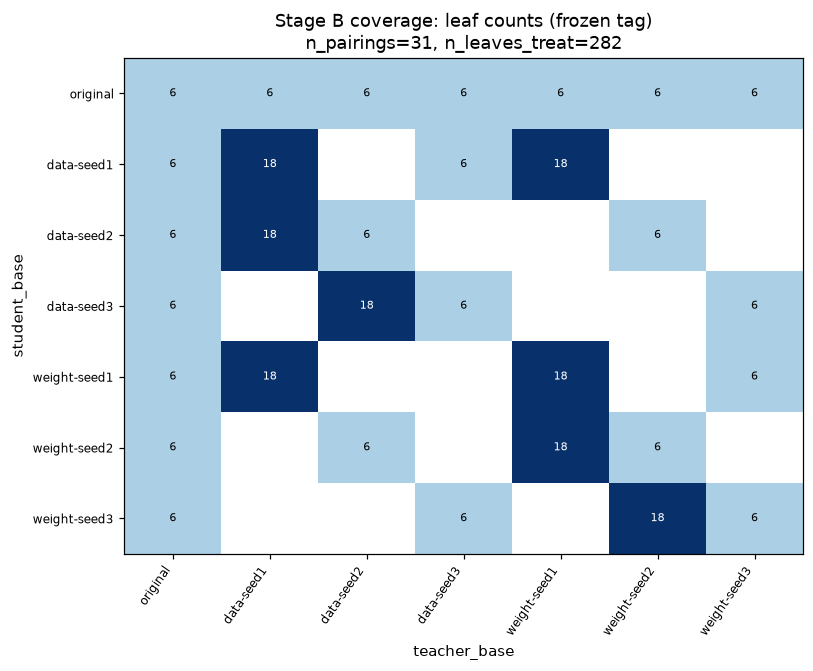

Structurally absent cells in 7x7: 18 (cyclic design — not every cross is trained)
Present cells: 31


In [8]:
# 7x7 teacher-init x student-init coverage map (leaf counts).
cov7 = (
    treat_m.groupby(["student_base", "teacher_base"], dropna=False)
    .size()
    .rename("n")
    .reset_index()
)
grid_n = (
    cov7.pivot(index="student_base", columns="teacher_base", values="n")
    .reindex(index=BASE_ORDER, columns=BASE_ORDER)
)
# Corner annotation grid for cell text.
pair_corner = (
    treat_m.drop_duplicates(["student_base", "teacher_base"])
    .set_index(["student_base", "teacher_base"])["corner"]
)
label_grid = grid_n.copy().astype(object)
for s in BASE_ORDER:
    for t in BASE_ORDER:
        v = grid_n.loc[s, t]
        if pd.isna(v):
            label_grid.loc[s, t] = np.nan
        else:
            c = pair_corner.get((s, t), "")
            short = {
                CORNER_SHARED_INIT_SHARED_STREAM: "SI∩SS",
                CORNER_DIFF_INIT_SHARED_STREAM: "DI∩SS",
                CORNER_SHARED_INIT_DIFF_STREAM: "SI∩DS",
                CORNER_DIFF_INIT_DIFF_STREAM: "DI∩DS",
            }.get(c, "?")
            label_grid.loc[s, t] = float(v)  # numeric for heatmap; annotate via fmt

fig, ax = plt.subplots(figsize=(7.5, 6.2))
aplots.annotated_heatmap(
    ax,
    grid_n.astype(float),
    cmap="Blues",
    vmin=0,
    vmax=float(np.nanmax(grid_n.values)),
    fmt=lambda v: f"{int(v)}",
    origin="upper",
)
ax.set_title(f"Stage B coverage: leaf counts (frozen tag)\nn_pairings=31, n_leaves_treat=282")
ax.set_xlabel("teacher_base")
ax.set_ylabel("student_base")
# Mark structurally absent cells (NaN) are already blank.
plt.tight_layout()
plt.show()

absent = [
    (s, t) for s in BASE_ORDER for t in BASE_ORDER
    if pd.isna(grid_n.loc[s, t])
]
print(f"Structurally absent cells in 7x7: {len(absent)} (cyclic design — not every cross is trained)")
print("Present cells:", int(grid_n.notna().sum().sum()))


## 3. Control floor by student init


End-of-run probe control floor:


animal,cat,dog
student_base,,
original,0.002404,0.008031
data-seed1,0.001984,0.007210
data-seed2,0.006650,0.015105
data-seed3,0.002372,0.004972
weight-seed1,0.001294,0.008071
weight-seed2,0.004898,0.009678
weight-seed3,0.002691,0.006503


Eval-grade control p_target on test:


animal,cat,dog
student_base,,
original,0.003185,0.009422
data-seed1,0.003743,0.010316
data-seed2,0.004830,0.008678
data-seed3,0.005159,0.006599
weight-seed1,0.004387,0.006567
weight-seed2,0.006821,0.014536
weight-seed3,0.003293,0.005822


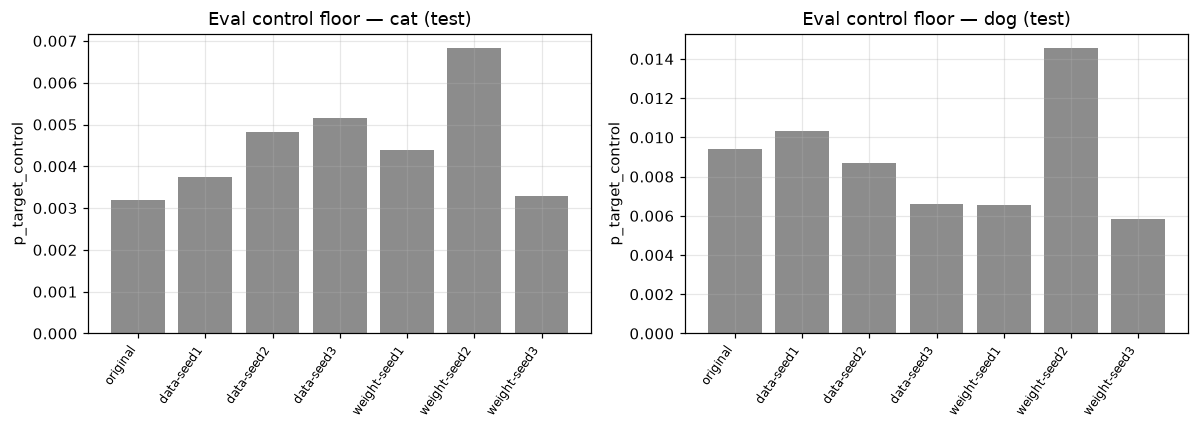

Mean control floor cat=0.0045 dog=0.0088 ratio_dog/cat=1.97
Keep all SL comparisons within-animal (dog floor can dwarf cat's).


In [9]:
eor = end_of_run_probes(probes)
eor_ctrl = eor[eor["is_control"]].copy()
eor_ctrl["student_base"] = eor_ctrl["model"].map(MODEL_TO_LABEL)

pref_ctrl = pref[pref["is_control"] & (pref["set"] == "test")].copy()
pref_ctrl["student_base"] = pref_ctrl["model"].map(MODEL_TO_LABEL)

floor_probe = (
    eor_ctrl.groupby(["animal", "student_base"], dropna=False)["p_target"]
    .agg(mean="mean", std="std", n="size")
    .reset_index()
)
floor_eval = (
    pref_ctrl.groupby(["animal", "student_base"], dropna=False)["p_target"]
    .agg(mean="mean", std="std", n="size")
    .reset_index()
)
print("End-of-run probe control floor:")
display(floor_probe.pivot(index="student_base", columns="animal", values="mean").reindex(BASE_ORDER))
print("Eval-grade control p_target on test:")
display(floor_eval.pivot(index="student_base", columns="animal", values="mean").reindex(BASE_ORDER))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=False)
for ax, animal in zip(axes, ("cat", "dog")):
    sub = floor_eval[floor_eval["animal"] == animal].set_index("student_base").reindex(BASE_ORDER)
    ax.bar(range(len(BASE_ORDER)), sub["mean"].values, color="0.55")
    ax.set_xticks(range(len(BASE_ORDER)))
    ax.set_xticklabels(BASE_ORDER, rotation=55, ha="right", fontsize=8)
    ax.set_title(f"Eval control floor — {animal} (test)")
    ax.set_ylabel("p_target_control")
plt.tight_layout()
plt.show()

cat_mean = float(floor_eval.loc[floor_eval.animal == "cat", "mean"].mean())
dog_mean = float(floor_eval.loc[floor_eval.animal == "dog", "mean"].mean())
print(f"Mean control floor cat={cat_mean:.4f} dog={dog_mean:.4f} ratio_dog/cat={dog_mean / cat_mean:.2f}")
print("Keep all SL comparisons within-animal (dog floor can dwarf cat's).")


## 4. Headline heatmaps

Teacher-init × student-init `subliminal_delta` on the held-out **`test`** set.
Diagonal cells are `same_init`; blanks are structurally untrained pairings.
Companion panel shows raw treatment `p_target` so the control subtraction is visible.


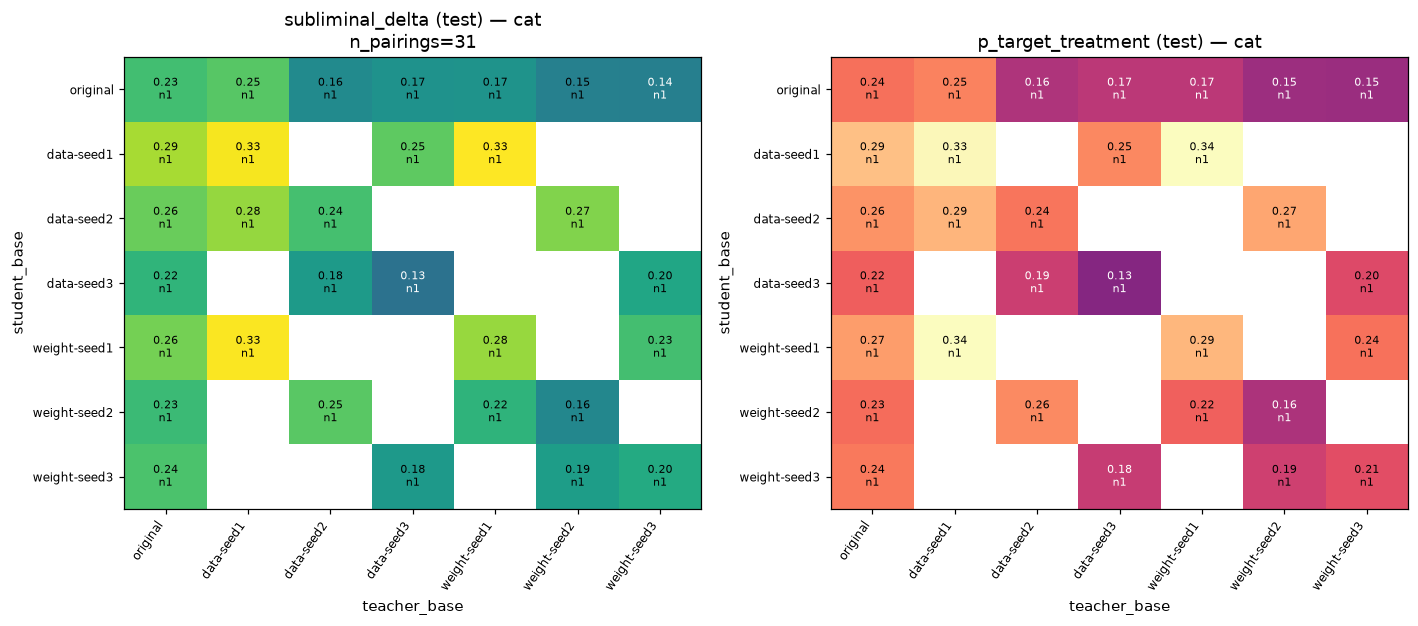

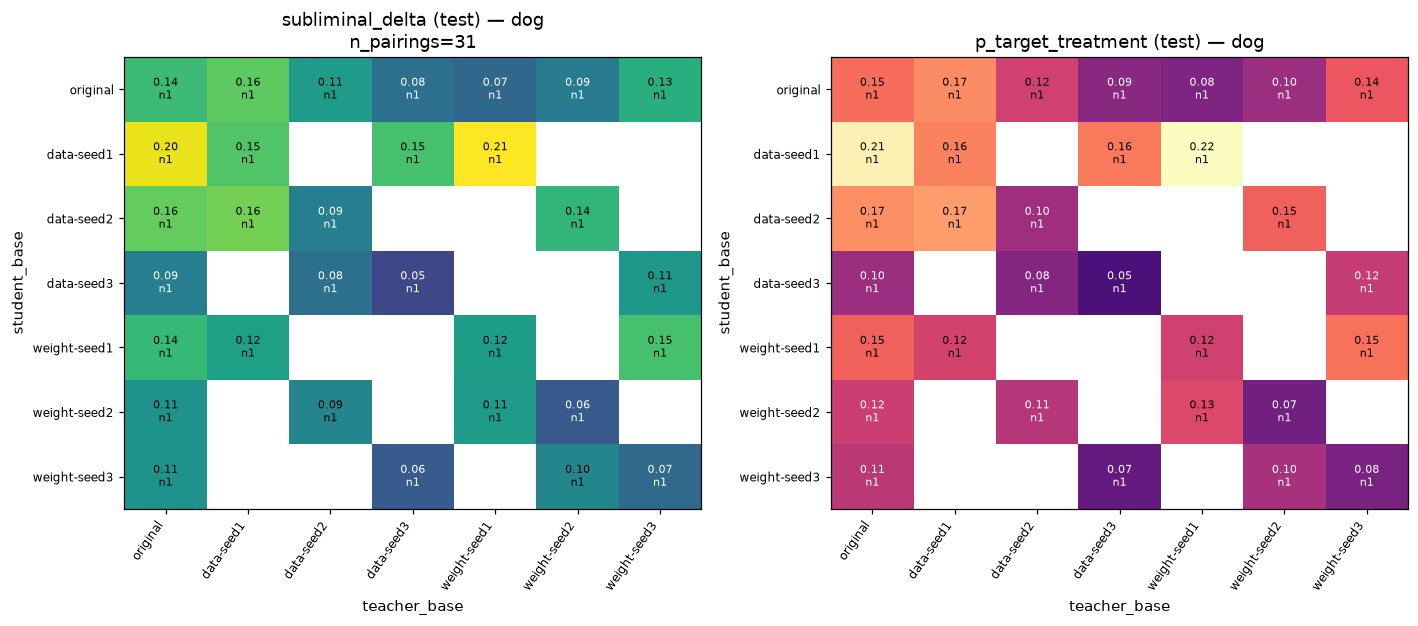

In [10]:
delta = subliminal_delta(pref)
delta_ann = annotate_pairing(delta)
delta_test = delta_ann[delta_ann["set"] == "test"].copy()
assert delta_test.drop_duplicates(["student_base", "teacher_base"]).shape[0] == 31

for animal in ("cat", "dog"):
    sub = delta_test[delta_test["animal"] == animal]
    g_delta = (
        sub.pivot_table(index="student_base", columns="teacher_base",
                        values="subliminal_delta", aggfunc="mean")
        .reindex(index=BASE_ORDER, columns=BASE_ORDER)
    )
    g_raw = (
        sub.pivot_table(index="student_base", columns="teacher_base",
                        values="p_target_treatment", aggfunc="mean")
        .reindex(index=BASE_ORDER, columns=BASE_ORDER)
    )
    g_n = (
        sub.groupby(["student_base", "teacher_base"]).size().unstack()
        .reindex(index=BASE_ORDER, columns=BASE_ORDER)
    )
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.8))
    vmax = float(np.nanmax(g_delta.values)) if np.isfinite(g_delta.values).any() else 1.0
    aplots.annotated_heatmap(
        axes[0], g_delta, cmap="viridis", vmin=0, vmax=max(vmax, 0.05),
        counts=g_n, fmt="{:.2f}", origin="upper",
    )
    axes[0].set_title(f"subliminal_delta (test) — {animal}\nn_pairings={sub.pairing.nunique()}")
    axes[0].set_xlabel("teacher_base")
    axes[0].set_ylabel("student_base")
    aplots.annotated_heatmap(
        axes[1], g_raw, cmap="magma", vmin=0,
        vmax=float(np.nanmax(g_raw.values)) if np.isfinite(g_raw.values).any() else 1.0,
        counts=g_n, fmt="{:.2f}", origin="upper",
    )
    axes[1].set_title(f"p_target_treatment (test) — {animal}")
    axes[1].set_xlabel("teacher_base")
    axes[1].set_ylabel("student_base")
    plt.tight_layout()
    plt.show()


## 5. The 2×2 factorial aggregation (headline)

**Decision rule (declared before numbers):** for each animal, compute the
pairing-cluster bootstrap CI of
`(DI∩SS mean) − (SI∩DS mean)` (= H1 cell − compare cell).

- **support H1** if the CI lies entirely above `+0.01`
- **support reverse** (shared-init cell higher) if the CI lies entirely below `−0.01`
- **null / H2-compatible** if `|contrast| < 0.01` and the CI covers 0
- else **inconclusive**

Bootstrap resamples **pairings** (cluster) with `np.random.default_rng(20260727)`.
A second variant resamples **leaves**. Animals are analysed separately; pooling
uses within-animal z-scores only.


Corner means + pairing-cluster bootstrap CIs:


,animal,corner,mean,ci_lo,ci_hi,n_pairings
0,cat,shared_init_shared_stream,0.223574,0.172010,0.270352,7
1,cat,diff_init_shared_stream,0.203251,0.175962,0.229192,9
2,cat,shared_init_diff_stream,0.228257,0.197711,0.256531,9
3,cat,diff_init_diff_stream,0.260317,0.212923,0.308441,6
4,dog,shared_init_shared_stream,0.096290,0.068536,0.125857,7
5,dog,diff_init_shared_stream,0.110746,0.096288,0.126150,9
6,dog,shared_init_diff_stream,0.131452,0.104206,0.158477,9
7,dog,diff_init_diff_stream,0.121206,0.088167,0.160308,6


Main effects + H1 contrast:


,animal,effect,mean,ci_lo,ci_hi,n
4,cat,ME_shared_stream,-0.028939,-0.065587,0.009038,31
5,cat,ME_shared_init,0.000131,-0.040452,0.040028,31
6,cat,H1_contrast_DI_SS_minus_SI_DS,-0.025006,-0.065875,0.014682,18
11,dog,ME_shared_stream,-0.022932,-0.049985,0.003480,31
12,dog,ME_shared_init,0.001138,-0.026732,0.029745,31
13,dog,H1_contrast_DI_SS_minus_SI_DS,-0.020706,-0.052114,0.010282,18


H1 summary:


,animal,contrast,ci_lo,ci_hi,verdict,mean_h1_cell,mean_compare_cell,p_boot_h1_greater,n_h1_cell,n_compare_cell
0,cat,-0.025006,-0.065875,0.014682,inconclusive,0.203251,0.228257,0.89525,9,9
1,dog,-0.020706,-0.052114,0.010282,inconclusive,0.110746,0.131452,0.89975,9,9


Leaf-resampled corner CIs:


,animal,corner,mean,ci_lo,ci_hi,n_leaves
0,cat,shared_init_shared_stream,0.253539,0.226388,0.279869,33
1,cat,diff_init_shared_stream,0.202851,0.186875,0.217498,39
2,cat,shared_init_diff_stream,0.229105,0.208902,0.248439,39
3,cat,diff_init_diff_stream,0.289416,0.263575,0.315511,30
4,dog,shared_init_shared_stream,0.109882,0.095598,0.124657,33
5,dog,diff_init_shared_stream,0.109067,0.099931,0.119104,39
6,dog,shared_init_diff_stream,0.128041,0.113365,0.143211,39
7,dog,diff_init_diff_stream,0.137878,0.117917,0.158798,30


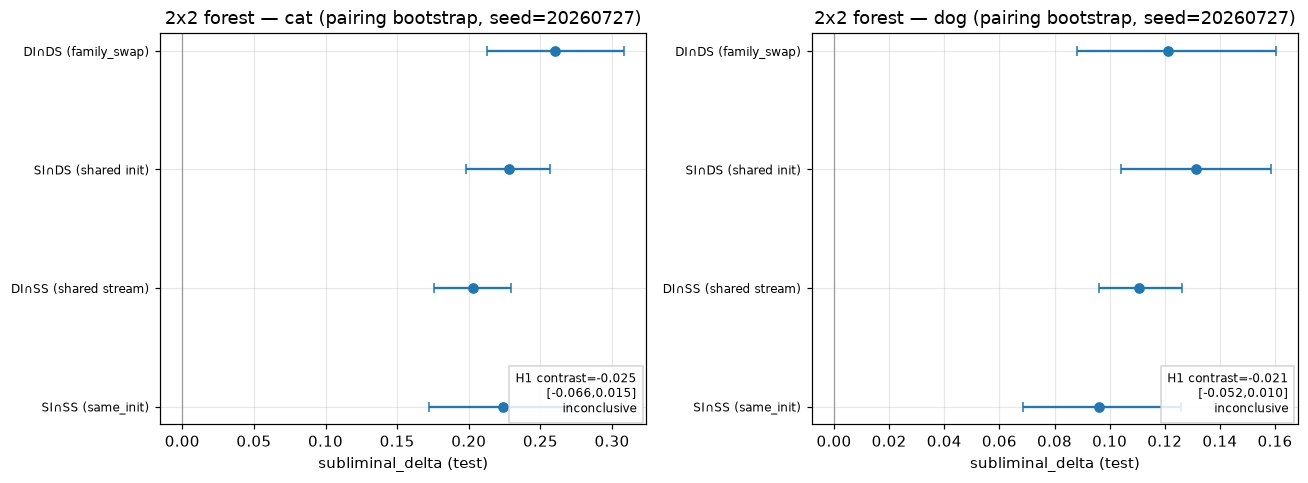

Pooled (within-animal z) corner means:


,animal,corner,mean,ci_lo,ci_hi,n_pairings
0,pooled,shared_init_shared_stream,-0.261282,-1.035070,0.468010,7
1,pooled,diff_init_shared_stream,-0.261324,-0.615834,0.111496,9
2,pooled,shared_init_diff_stream,0.216366,-0.369655,0.783149,9
3,pooled,diff_init_diff_stream,0.372265,-0.405746,1.186843,6


In [11]:
pd_delta = pairing_delta_frame(delta, "test")

# Pairing-level bootstrap tables.
corner_tables = []
effect_tables = []
h1_rows = []
for animal in ("cat", "dog"):
    bt = corner_bootstrap_table(pd_delta, animal=animal, n_boot=2000, seed=BOOTSTRAP_SEED)
    corner_tables.append(bt)
    me = main_effects_table(pd_delta, animal=animal, n_boot=2000, seed=BOOTSTRAP_SEED)
    effect_tables.append(me)
    row = me[me["effect"] == "H1_contrast_DI_SS_minus_SI_DS"].iloc[0]
    verd = verdict_from_contrast(float(row["mean"]), float(row["ci_lo"]), float(row["ci_hi"]))
    h1_rows.append({
        "animal": animal,
        "contrast": float(row["mean"]),
        "ci_lo": float(row["ci_lo"]),
        "ci_hi": float(row["ci_hi"]),
        "verdict": verd,
        **{k: h1_sign_test(pd_delta, animal)[k]
           for k in ("mean_h1_cell", "mean_compare_cell", "p_boot_h1_greater",
                     "n_h1_cell", "n_compare_cell")},
    })

corner_ci = pd.concat(corner_tables, ignore_index=True)
effects = pd.concat(effect_tables, ignore_index=True)
h1_summary = pd.DataFrame(h1_rows)
print("Corner means + pairing-cluster bootstrap CIs:")
display(corner_ci)
print("Main effects + H1 contrast:")
display(effects[effects["effect"].str.match(r"ME_|H1_")])
print("H1 summary:")
display(h1_summary)

# Leaf-level bootstrap variant: explode per_seed from preference for test set.
# Use pref_leaf treatment minus matched control leaf mean per (animal, model, gseed).
pleaf_t = annotate_pairing(pref_leaf[(~pref_leaf["is_control"]) & (pref_leaf["set"] == "test")].copy())
pleaf_c = pref_leaf[(pref_leaf["is_control"]) & (pref_leaf["set"] == "test")].copy()
ctrl_by = pleaf_c.groupby(["animal", "model", "gseed"])["p_target"].mean()
pleaf_t["p_target_control"] = [
    ctrl_by.get((a, m, g), np.nan)
    for a, m, g in zip(pleaf_t["animal"], pleaf_t["model"], pleaf_t["gseed"])
]
pleaf_t["subliminal_delta"] = pleaf_t["p_target"] - pleaf_t["p_target_control"]

leaf_boot_rows = []
for animal in ("cat", "dog"):
    for corner in CORNER_ORDER:
        vals = pleaf_t[(pleaf_t.animal == animal) & (pleaf_t.corner == corner)]["subliminal_delta"]
        m, lo, hi, n = cluster_bootstrap_ci(vals.values, n_boot=2000, seed=BOOTSTRAP_SEED)
        leaf_boot_rows.append({"animal": animal, "corner": corner, "mean": m,
                               "ci_lo": lo, "ci_hi": hi, "n_leaves": n})
leaf_ci = pd.DataFrame(leaf_boot_rows)
print("Leaf-resampled corner CIs:")
display(leaf_ci)

# Forest plot.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=False)
for ax, animal in zip(axes, ("cat", "dog")):
    sub = corner_ci[corner_ci.animal == animal].set_index("corner").reindex(CORNER_ORDER)
    y = np.arange(len(CORNER_ORDER))
    ax.errorbar(
        sub["mean"], y,
        xerr=[sub["mean"] - sub["ci_lo"], sub["ci_hi"] - sub["mean"]],
        fmt="o", color="C0", capsize=3,
    )
    ax.axvline(0, color="0.6", lw=0.8)
    ax.set_yticks(y)
    ax.set_yticklabels([CORNER_SHORT[c].replace("\n", " ") for c in CORNER_ORDER], fontsize=8)
    ax.set_xlabel("subliminal_delta (test)")
    ax.set_title(f"2x2 forest — {animal} (pairing bootstrap, seed={BOOTSTRAP_SEED})")
    # print H1 verdict on axes
    hv = h1_summary[h1_summary.animal == animal].iloc[0]
    ax.text(
        0.98, 0.02,
        f"H1 contrast={hv.contrast:.3f}\n[{hv.ci_lo:.3f},{hv.ci_hi:.3f}]\n{hv.verdict}",
        transform=ax.transAxes, ha="right", va="bottom", fontsize=8,
        bbox={"facecolor": "white", "alpha": 0.85, "edgecolor": "0.8"},
    )
plt.tight_layout()
plt.show()

# Pooled across animals via within-animal z-scores (cat and dog floors differ,
# so raw deltas are not poolable).
z = standardize_within_animal(pd_delta, "subliminal_delta")
z["subliminal_delta"] = z["subliminal_delta_z"]
pooled = corner_bootstrap_table(z, animal=None, n_boot=2000, seed=BOOTSTRAP_SEED)
print("Pooled (within-animal z) corner means:")
display(pooled)


## 6. Group-level breakdown + seed0 replication check


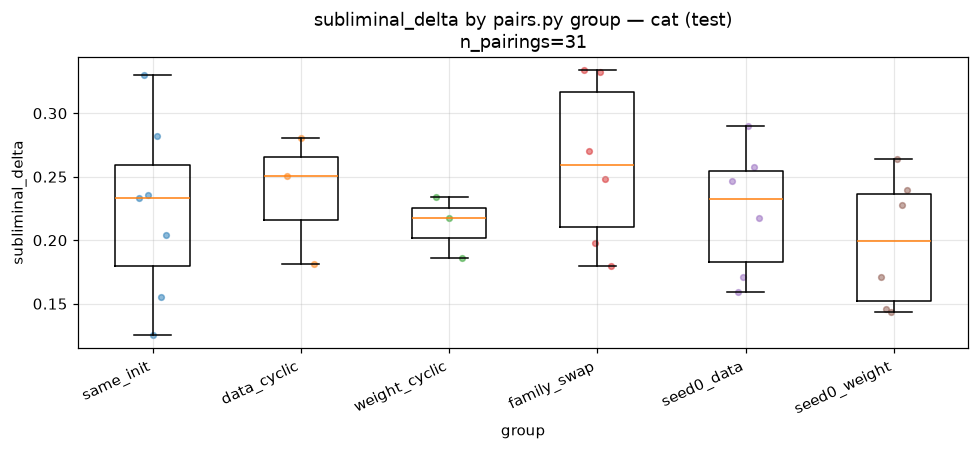

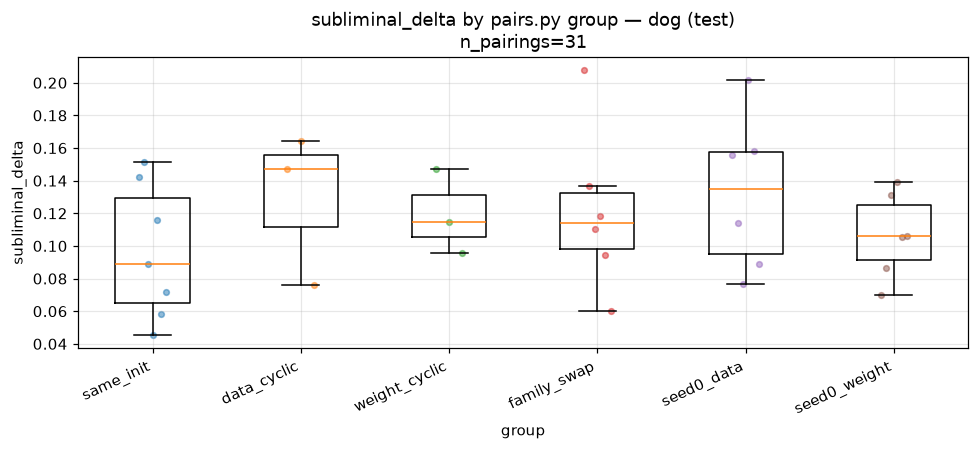

Replication check: seed0_* vs cyclic (factor-equivalent claim)


,animal,seed0_group,cyclic_group,mean_seed0,mean_cyclic,diff_seed0_minus_cyclic,n_seed0,n_cyclic
0,cat,seed0_data,data_cyclic,0.223636,0.237500,-0.013864,6,3
1,cat,seed0_weight,weight_cyclic,0.198574,0.212604,-0.014030,6,3
2,dog,seed0_data,data_cyclic,0.132547,0.129260,0.003287,6,3
3,dog,seed0_weight,weight_cyclic,0.106468,0.119302,-0.012834,6,3


In [12]:
# Per-pairing points by pairs.py group.
group_order = list(CORNER_GROUPS)
for animal in ("cat", "dog"):
    sub = pd_delta[pd_delta["animal"] == animal].copy()
    sub["group"] = pd.Categorical(sub["group"], categories=group_order, ordered=True)
    fig, ax = plt.subplots(figsize=(9, 4.2))
    aplots.strip_box(
        ax,
        groups_for_strip(sub, "group", "subliminal_delta", group_order),
        group_order,
    )
    ax.set_title(f"subliminal_delta by pairs.py group — {animal} (test)\nn_pairings={sub.pairing.nunique()}")
    ax.set_xlabel("group")
    ax.set_ylabel("subliminal_delta")
    ax.tick_params(axis="x", rotation=25)
    plt.tight_layout()
    plt.show()

print("Replication check: seed0_* vs cyclic (factor-equivalent claim)")
repl_rows = []
for animal in ("cat", "dog"):
    d = pd_delta[pd_delta.animal == animal]
    for g_seed0, g_cyc in (
        (GROUP_SEED0_DATA, GROUP_DATA_CYCLIC),
        (GROUP_SEED0_WEIGHT, GROUP_WEIGHT_CYCLIC),
    ):
        a = d.loc[d.group == g_seed0, "subliminal_delta"]
        b = d.loc[d.group == g_cyc, "subliminal_delta"]
        repl_rows.append({
            "animal": animal,
            "seed0_group": g_seed0,
            "cyclic_group": g_cyc,
            "mean_seed0": float(a.mean()),
            "mean_cyclic": float(b.mean()),
            "diff_seed0_minus_cyclic": float(a.mean() - b.mean()),
            "n_seed0": int(a.size),
            "n_cyclic": int(b.size),
        })
repl = pd.DataFrame(repl_rows)
display(repl)


## 7. Teacher-strength control (critical confound)

`teacher_p_target` varies strongly by teacher init. Transfer comparisons that
ignore this are confounded. Below: (a) teacher strength by base, (b) scatter of
`subliminal_delta` vs teacher strength with Spearman, (c) notebook-local
**transfer efficiency** `subliminal_delta / teacher_p_target` (novel — not a
pipeline SSOT metric), (d) corner contrast after residualising delta on teacher
strength. We then re-apply the §5 decision rule to the residual contrast.


Mean teacher_p_target by (animal, teacher_base):


animal,cat,dog
teacher_base,,
original,0.164646,0.108128
data-seed1,0.201261,0.116562
data-seed2,0.116827,0.181214
data-seed3,0.098678,0.085518
weight-seed1,0.107902,0.086987
weight-seed2,0.139590,0.103495
weight-seed3,0.116445,0.084467


Control leaf teacher_p_target (should be ~floor): {'cat': 0.003423296453001967, 'dog': 0.008552033640548221}


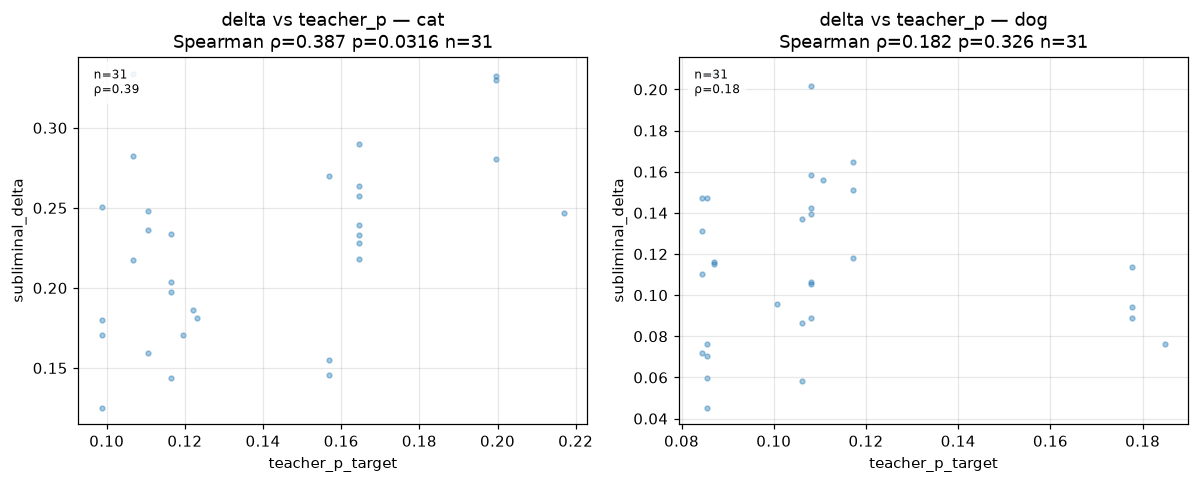

Transfer efficiency by corner:


,animal,corner,mean,std,count
0,cat,diff_init_diff_stream,2.047287,0.572792,6
1,cat,diff_init_shared_stream,1.511996,0.349653,9
2,cat,shared_init_diff_stream,1.597006,0.402236,9
3,cat,shared_init_shared_stream,1.693996,0.557439,7
4,dog,diff_init_diff_stream,1.202991,0.656161,6
5,dog,diff_init_shared_stream,1.160520,0.331669,9
6,dog,shared_init_diff_stream,1.181383,0.504264,9
7,dog,shared_init_shared_stream,0.909933,0.394876,7


H1 contrast after residualising on teacher_p_target:


,animal,contrast_resid,ci_lo,ci_hi,verdict,slope,intercept
0,cat,-0.016021,-0.051263,0.015833,inconclusive,0.738965,0.123270
1,dog,-0.023492,-0.053204,0.007040,inconclusive,-0.117924,0.128387


,animal,corner,mean,ci_lo,ci_hi,n
0,cat,shared_init_shared_stream,1.693996,1.321885,2.092976,7
1,cat,diff_init_shared_stream,1.511996,1.308115,1.733044,9
2,cat,shared_init_diff_stream,1.597006,1.385100,1.859134,9
3,cat,diff_init_diff_stream,2.047287,1.711627,2.509492,6
4,dog,shared_init_shared_stream,0.909933,0.640632,1.193705,7
5,dog,diff_init_shared_stream,1.160520,0.970206,1.370295,9
6,dog,shared_init_diff_stream,1.181383,0.871148,1.475866,9
7,dog,diff_init_diff_stream,1.202991,0.786366,1.712514,6


In [13]:
eor_t = annotate_pairing(eor[~eor["is_control"]].copy())
tp = (
    eor_t.groupby(["animal", "teacher_base"], dropna=False)["teacher_p_target"]
    .mean()
    .reset_index()
)
print("Mean teacher_p_target by (animal, teacher_base):")
display(tp.pivot(index="teacher_base", columns="animal", values="teacher_p_target").reindex(BASE_ORDER))

# Control leaves for reference.
eor_c = eor[eor["is_control"]].copy()
print("Control leaf teacher_p_target (should be ~floor):",
      eor_c.groupby("animal")["teacher_p_target"].mean().to_dict())

# Join teacher strength at pairing level: the mean over exactly the leaves that
# `subliminal_delta` averaged (all teacher ftseeds of that pairing).
tp_pair = (
    eor_t.groupby(["animal", "student_base", "teacher_base"], dropna=False)[
        "teacher_p_target"
    ]
    .mean()
    .reset_index()
)
m = pd_delta.merge(tp_pair, on=["animal", "student_base", "teacher_base"], how="left")
assert m["teacher_p_target"].notna().all()
m["transfer_eff"] = [
    transfer_efficiency(d, t) for d, t in zip(m["subliminal_delta"], m["teacher_p_target"])
]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, animal in zip(axes, ("cat", "dog")):
    s = m[m.animal == animal]
    aplots.identity_scatter(
        ax, s, "teacher_p_target", "subliminal_delta",
        diag_lim=None, stat="spearman", title_stats=False, textbox=True,
    )
    rho = spearmanr(s["teacher_p_target"], s["subliminal_delta"])
    ax.set_title(f"delta vs teacher_p — {animal}\nSpearman ρ={rho.statistic:.3f} p={rho.pvalue:.3g} n={len(s)}")
    ax.set_xlabel("teacher_p_target")
    ax.set_ylabel("subliminal_delta")
plt.tight_layout()
plt.show()

print("Transfer efficiency by corner:")
display(
    m.groupby(["animal", "corner"])["transfer_eff"].agg(["mean", "std", "count"]).reset_index()
)

# Residualise within animal: delta ~ a + b * teacher_p
resid_rows = []
h1_resid = []
for animal in ("cat", "dog"):
    s = m[m.animal == animal].copy()
    x = s["teacher_p_target"].values.astype(float)
    y = s["subliminal_delta"].values.astype(float)
    b1, b0 = np.polyfit(x, y, 1)
    s["delta_resid"] = y - (b0 + b1 * x)
    resid_rows.append(s)
    a = s.loc[s.corner == H1_CELL].groupby("pairing")["delta_resid"].mean().values
    b = s.loc[s.corner == H1_COMPARE].groupby("pairing")["delta_resid"].mean().values
    rng = np.random.default_rng(BOOTSTRAP_SEED)
    obs = float(a.mean() - b.mean())
    boots = [
        float(rng.choice(a, size=a.size, replace=True).mean()
              - rng.choice(b, size=b.size, replace=True).mean())
        for _ in range(2000)
    ]
    lo, hi = np.quantile(boots, [0.025, 0.975])
    verd = verdict_from_contrast(obs, float(lo), float(hi))
    h1_resid.append({
        "animal": animal, "contrast_resid": obs, "ci_lo": float(lo), "ci_hi": float(hi),
        "verdict": verd, "slope": float(b1), "intercept": float(b0),
    })
m_resid = pd.concat(resid_rows, ignore_index=True)
h1_after_teacher = pd.DataFrame(h1_resid)
print("H1 contrast after residualising on teacher_p_target:")
display(h1_after_teacher)

# Efficiency corner forest
eff_ci = []
for animal in ("cat", "dog"):
    for corner in CORNER_ORDER:
        vals = m.loc[(m.animal == animal) & (m.corner == corner)].groupby("pairing")["transfer_eff"].mean()
        mu, lo, hi, n = cluster_bootstrap_ci(vals.values, n_boot=2000, seed=BOOTSTRAP_SEED)
        eff_ci.append({"animal": animal, "corner": corner, "mean": mu, "ci_lo": lo, "ci_hi": hi, "n": n})
display(pd.DataFrame(eff_ci))


## 8. Student-base confound control

Some student bases may simply be more absorbent. For each student base, subtract
its own `same_init` pairing delta from each of its cross-init pairing deltas,
then aggregate those paired differences by corner. This removes the student main
effect.


Within-student-base paired differences (cross − same_init):


,animal,corner,mean,std,count
0,cat,diff_init_diff_stream,0.038300,0.043260,6
1,cat,diff_init_shared_stream,-0.016876,0.061514,9
2,cat,shared_init_diff_stream,-0.002917,0.062710,9
3,dog,diff_init_diff_stream,0.032591,0.031039,6
4,dog,diff_init_shared_stream,0.008569,0.045447,9
5,dog,shared_init_diff_stream,0.020581,0.046743,9


Student-base marginal means (subliminal_delta, test):


animal,cat,dog
student_base,,
original,0.181431,0.110897
data-seed1,0.300993,0.176897
data-seed2,0.260999,0.137171
data-seed3,0.180490,0.080217
weight-seed1,0.278023,0.130249
weight-seed2,0.212182,0.093182
weight-seed3,0.202433,0.083475


Teacher-base marginal means:


animal,cat,dog
teacher_base,,
original,0.247011,0.134642
data-seed1,0.297345,0.147437
data-seed2,0.206227,0.093312
data-seed3,0.181580,0.082188
weight-seed1,0.251093,0.127243
weight-seed2,0.189333,0.094276
weight-seed3,0.194777,0.115181


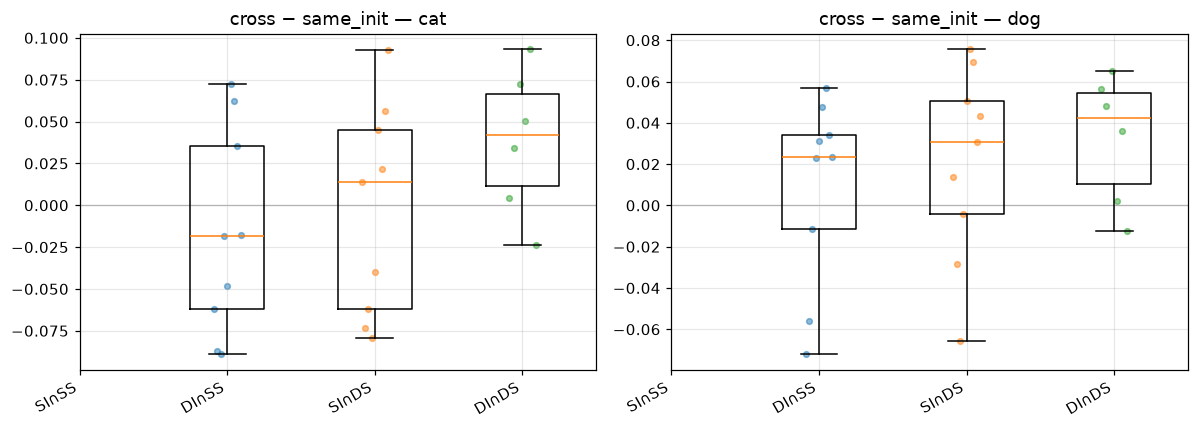

In [14]:
paired_diff_rows = []
for animal in ("cat", "dog"):
    d = pd_delta[pd_delta.animal == animal]
    same = (
        d[d.group == GROUP_SAME]
        .set_index("student_base")["subliminal_delta"]
        .to_dict()
    )
    for _, row in d.iterrows():
        if row["group"] == GROUP_SAME:
            continue
        base_delta = same.get(row["student_base"])
        if base_delta is None:
            continue
        paired_diff_rows.append({
            "animal": animal,
            "student_base": row["student_base"],
            "teacher_base": row["teacher_base"],
            "corner": row["corner"],
            "group": row["group"],
            "delta": row["subliminal_delta"],
            "same_init_delta": base_delta,
            "delta_minus_same": row["subliminal_delta"] - base_delta,
        })
paired_diff = pd.DataFrame(paired_diff_rows)
print("Within-student-base paired differences (cross − same_init):")
display(
    paired_diff.groupby(["animal", "corner"])["delta_minus_same"]
    .agg(["mean", "std", "count"])
    .reset_index()
)

print("Student-base marginal means (subliminal_delta, test):")
display(
    pd_delta.groupby(["animal", "student_base"])["subliminal_delta"]
    .mean()
    .unstack(0)
    .reindex(BASE_ORDER)
)
print("Teacher-base marginal means:")
display(
    pd_delta.groupby(["animal", "teacher_base"])["subliminal_delta"]
    .mean()
    .unstack(0)
    .reindex(BASE_ORDER)
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, animal in zip(axes, ("cat", "dog")):
    sub = paired_diff[paired_diff.animal == animal]
    aplots.strip_box(
        ax,
        groups_for_strip(sub, "corner", "delta_minus_same", CORNER_ORDER),
        [CORNER_SHORT[c].split("\n")[0] for c in CORNER_ORDER],
        zero_line=True,
    )
    ax.set_title(f"cross − same_init — {animal}")
    ax.tick_params(axis="x", labelrotation=30)
plt.tight_layout()
plt.show()


## 9. Direction asymmetry (A→B vs B→A)


Bidirectional undirected edges: 18 rows (animal × edge)


,animal,group,n
0,cat,family_swap,3
1,cat,seed0_data,3
2,cat,seed0_weight,3
3,dog,family_swap,3
4,dog,seed0_data,3
5,dog,seed0_weight,3


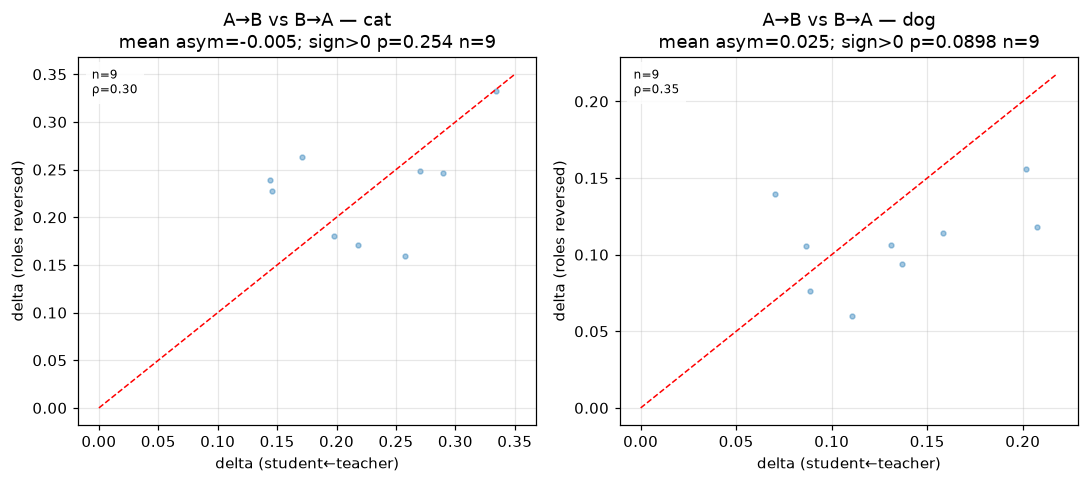

,animal,n_edges,mean_asym,frac_forward_higher,sign_p_greater
0,cat,9,-0.004603,0.666667,0.253906
1,dog,9,0.024647,0.777778,0.089844


In [15]:
# Pairs that exist in both directions.
forward = pd_delta.copy()
forward["rev_pairing"] = forward["teacher_base"] + "|" + forward["student_base"]
rev = pd_delta.rename(columns={
    "subliminal_delta": "delta_rev",
    "pairing": "rev_pairing",
})[["animal", "rev_pairing", "delta_rev"]]
both = forward.merge(rev, on=["animal", "rev_pairing"], how="inner")
# Keep each undirected edge once: student_base < teacher_base lexicographically.
both = both[both["student_base"] < both["teacher_base"]].copy()
print(f"Bidirectional undirected edges: {len(both)} rows (animal × edge)")
display(both.groupby(["animal", "group"]).size().rename("n").reset_index())

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, animal in zip(axes, ("cat", "dog")):
    s = both[both.animal == animal]
    if s.empty:
        ax.set_title(f"{animal}: no bidirectional edges")
        continue
    aplots.identity_scatter(
        ax, s, "subliminal_delta", "delta_rev",
        diag_lim=(0, max(s.subliminal_delta.max(), s.delta_rev.max()) * 1.05),
        stat="spearman", textbox=True, title_stats=False,
    )
    asym = s["subliminal_delta"] - s["delta_rev"]
    st_pos = sign_test(list(asym.values), 0.0, "greater")
    ax.set_title(
        f"A→B vs B→A — {animal}\n"
        f"mean asym={asym.mean():.3f}; sign>0 p={st_pos.p_value:.3g} n={len(s)}"
    )
    ax.set_xlabel("delta (student←teacher)")
    ax.set_ylabel("delta (roles reversed)")
plt.tight_layout()
plt.show()

asym_summary = []
for animal in ("cat", "dog"):
    s = both[both.animal == animal]
    asym = s["subliminal_delta"] - s["delta_rev"]
    asym_summary.append({
        "animal": animal,
        "n_edges": len(s),
        "mean_asym": float(asym.mean()) if len(s) else float("nan"),
        "frac_forward_higher": float((asym > 0).mean()) if len(s) else float("nan"),
        "sign_p_greater": sign_test(list(asym.values), 0.0, "greater").p_value if len(s) else float("nan"),
    })
display(pd.DataFrame(asym_summary))


## 10. Seeds and stochasticity

On the **8 headline pairings** (full 3 tfs × 3 gseed = 9 leaves each), decompose
leaf-level `test` `p_target` into pairing / teacher-ftseed-within-pairing /
student-gseed-within-(pairing, tfs) sums of squares, run per animal. Because
(pairing, tfs, gseed) identifies a single leaf, the finest level exhausts the
variance and the reported `residual` row is **structurally zero** — the
informative output is the `frac_ss` split across the three seed/design levels,
not an F test. Then bootstrap over leaves for **rank-stability** of the corner
ordering.

**Power limits (honest):** 3 gseeds everywhere; only 1 tfs for 23 of the 31
pairings (extension tier), so the teacher-seed component is estimated from the
headline tier alone (8 pairings × 9 leaves per animal).

Headline leaves: 144 pairings 8 expected 144

ANOVA-style SS — cat headline test p_target:


,animal,source,ss,df,ms,frac_ss
0,cat,pairing,0.261024,7,0.037289,0.674506
1,cat,tfs,0.040623,16,0.002539,0.104972
2,cat,gseed,0.085339,48,0.001778,0.220522
3,cat,residual,0.000000,0,NaN,0.000000
4,cat,total,0.386986,71,NaN,1.000000



ANOVA-style SS — dog headline test p_target:


,animal,source,ss,df,ms,frac_ss
0,dog,pairing,0.117182,7,0.016740,0.691517
1,dog,tfs,0.019675,16,0.001230,0.116109
2,dog,gseed,0.032599,48,0.000679,0.192374
3,dog,residual,0.000000,0,NaN,0.000000
4,dog,total,0.169457,71,NaN,1.000000


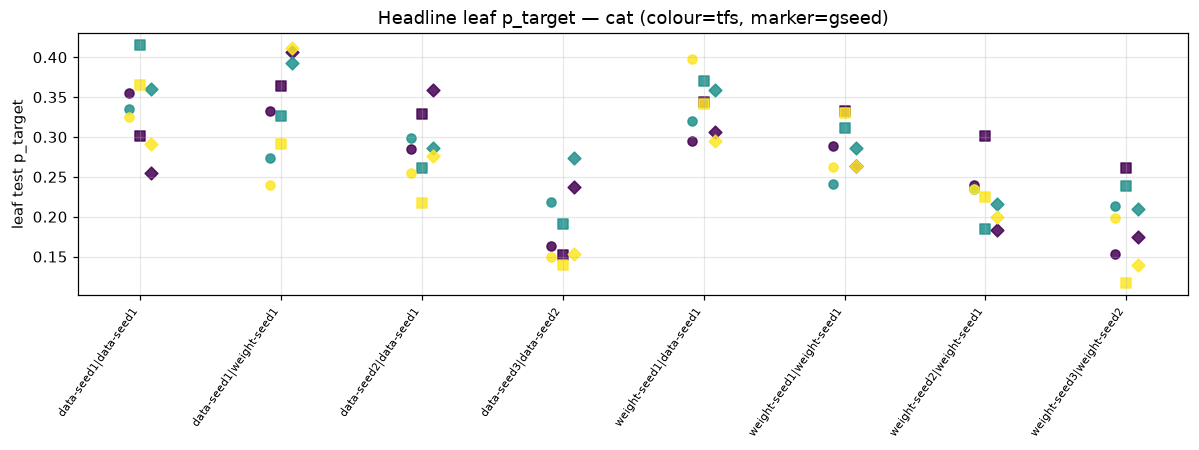

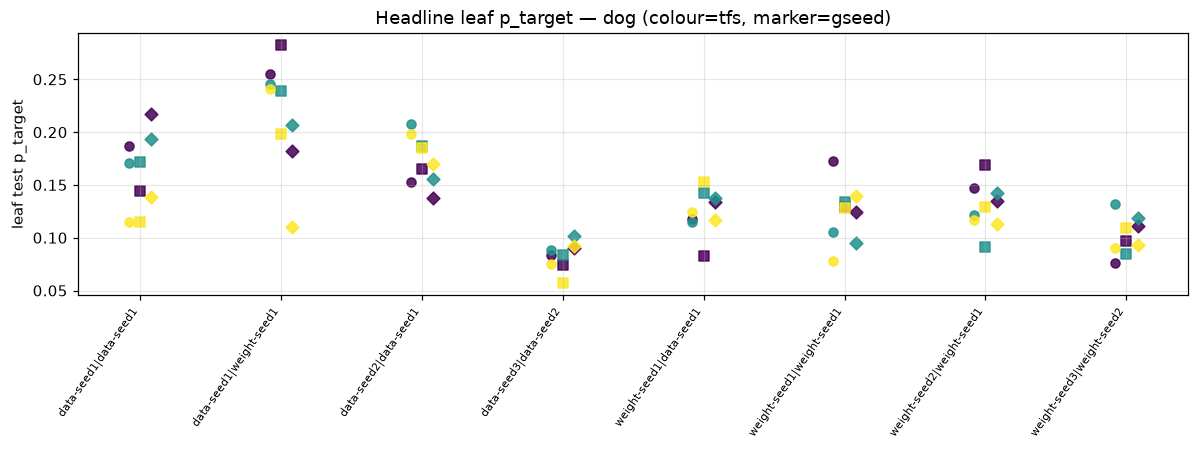

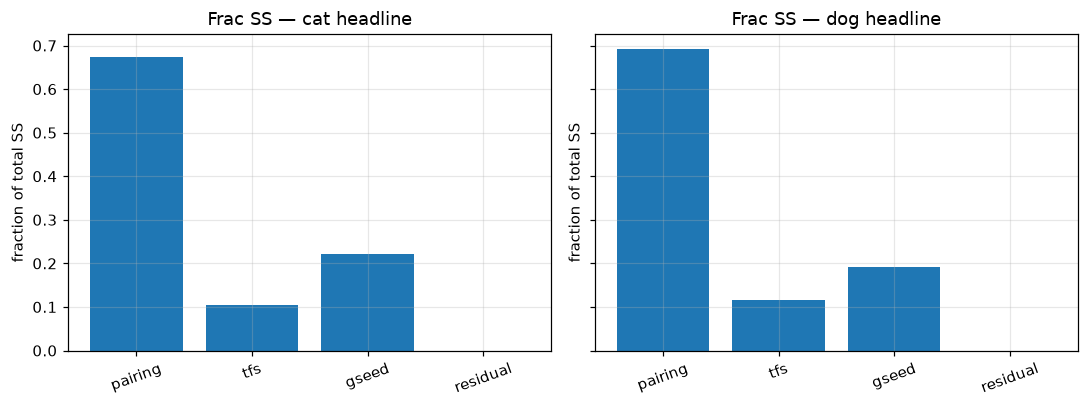

Corner rank stability (bootstrap over leaves):


,animal,observed_order,frac_preserved,n_boot
0,cat,"(diff_init_diff_stream, shared_init_diff_strea...",0.661,1000
1,dog,"(shared_init_diff_stream, diff_init_diff_strea...",0.954,1000


In [16]:
leaf_test = annotate_pairing(
    pref_leaf[(~pref_leaf.is_control) & (pref_leaf["set"] == "test")].copy()
)
leaf_test["tfs"] = leaf_test["teacher_ftseed"].astype(int)
head_leaves = leaf_test[leaf_test["headline"]].copy()
print("Headline leaves:", len(head_leaves),
      "pairings", head_leaves.pairing.nunique(),
      "expected", 8 * 2 * 9)

anova_rows = []
for animal in ("cat", "dog"):
    sub = head_leaves[head_leaves.animal == animal]
    a = nested_anova_ss(sub, "p_target", ["pairing", "tfs", "gseed"])
    a.insert(0, "animal", animal)
    anova_rows.append(a)
    print(f"\nANOVA-style SS — {animal} headline test p_target:")
    display(a)

anova_all = pd.concat(anova_rows, ignore_index=True)

# Per-pairing leaf strip: colour by tfs, mark by gseed.
for animal in ("cat", "dog"):
    sub = head_leaves[head_leaves.animal == animal].copy()
    sub = sub.sort_values(["pairing", "tfs", "gseed"])
    fig, ax = plt.subplots(figsize=(11, 4.2))
    pairings = list(sub.pairing.unique())
    xpos = {p: i for i, p in enumerate(pairings)}
    markers = {0: "o", 1: "s", 2: "D"}
    for _, r in sub.iterrows():
        ax.scatter(
            xpos[r.pairing] + (r.gseed - 1) * 0.08,
            r.p_target,
            color=plt.cm.viridis(r.tfs / 2.0),
            marker=markers.get(int(r.gseed), "o"),
            s=35, alpha=0.85,
        )
    ax.set_xticks(range(len(pairings)))
    ax.set_xticklabels(pairings, rotation=55, ha="right", fontsize=7)
    ax.set_ylabel("leaf test p_target")
    ax.set_title(f"Headline leaf p_target — {animal} (colour=tfs, marker=gseed)")
    plt.tight_layout()
    plt.show()

# Variance decomposition bars.
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, animal in zip(axes, ("cat", "dog")):
    a = anova_all[(anova_all.animal == animal) & (anova_all.source != "total")]
    ax.bar(a["source"], a["frac_ss"], color="C0")
    ax.set_title(f"Frac SS — {animal} headline")
    ax.set_ylabel("fraction of total SS")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

# Rank stability on leaf-level deltas.
ctrl_leaf = pref_leaf[(pref_leaf.is_control) & (pref_leaf.set == "test")]
ctrl_map = ctrl_leaf.groupby(["animal", "model", "gseed"])["p_target"].mean()
leaf_d = leaf_test.copy()
leaf_d["subliminal_delta"] = [
    p - ctrl_map.get((a, m, g), np.nan)
    for p, a, m, g in zip(leaf_d.p_target, leaf_d.animal, leaf_d.model, leaf_d.gseed)
]
rank_rows = [rank_stability(leaf_d, animal=a, n_boot=1000, seed=BOOTSTRAP_SEED) for a in ("cat", "dog")]
rank_df = pd.DataFrame(rank_rows)
print("Corner rank stability (bootstrap over leaves):")
display(rank_df)


## 11. Prompt-set generalization ladder

`subliminal_delta` across the six prompt sets × four corners × two animals.
`register` has 40 prompts; the rest have 50. Sign tests are grouped by set
(and optionally by corner).


n_prompts by set: {'consensus': [50], 'dislike': [50], 'favorite': [50], 'register': [40], 'test': [50], 'validation': [50]}


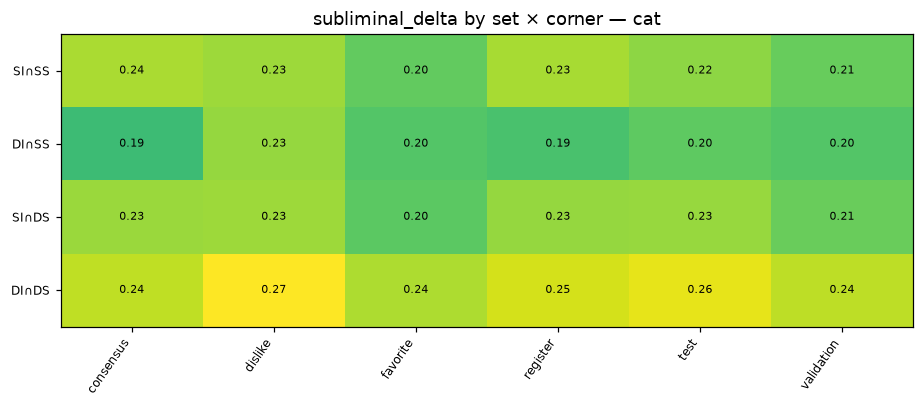

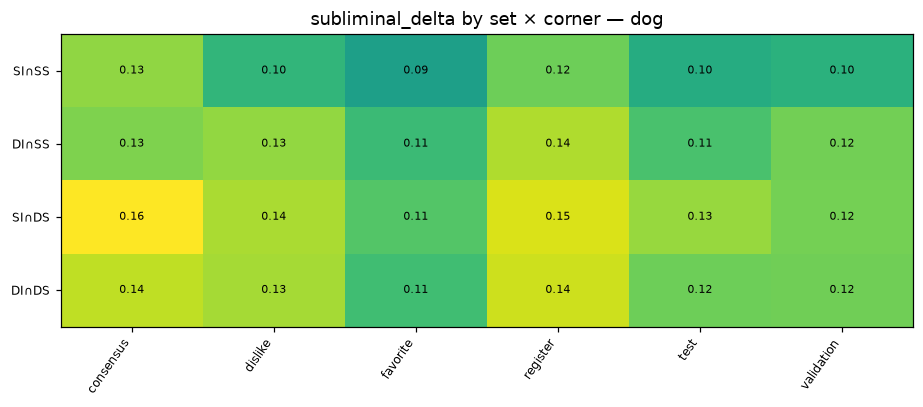

Sign test by set:


,set,n_configs,n_positive,frac_positive,p_value
0,consensus,62,62,1.0,2.168404e-19
1,dislike,62,62,1.0,2.168404e-19
2,favorite,62,62,1.0,2.168404e-19
3,register,62,62,1.0,2.168404e-19
4,test,62,62,1.0,2.168404e-19
5,validation,62,62,1.0,2.168404e-19


Sign test by set × corner (frac_positive):


set,consensus,dislike,favorite,register,test,validation
corner,,,,,,
shared_init_shared_stream,1.0,1.0,1.0,1.0,1.0,1.0
diff_init_shared_stream,1.0,1.0,1.0,1.0,1.0,1.0
shared_init_diff_stream,1.0,1.0,1.0,1.0,1.0,1.0
diff_init_diff_stream,1.0,1.0,1.0,1.0,1.0,1.0


In [17]:
delta_all = delta_ann
n_by_set = (
    pref[~pref.is_control]
    .groupby("set")["n_prompts"]
    .agg(lambda s: sorted(set(s)))
    .rename("n_prompts_values")
)
print("n_prompts by set:", n_by_set.to_dict())

ladder = (
    delta_all.groupby(["animal", "set", "corner"], dropna=False)["subliminal_delta"]
    .mean()
    .reset_index()
)
for animal in ("cat", "dog"):
    sub = ladder[ladder.animal == animal]
    grid = (
        sub.pivot(index="corner", columns="set", values="subliminal_delta")
        .reindex(index=CORNER_ORDER, columns=PROMPT_SETS)
    )
    fig, ax = plt.subplots(figsize=(8.5, 3.8))
    aplots.annotated_heatmap(
        ax, grid, cmap="viridis", vmin=0,
        vmax=float(np.nanmax(grid.values)),
        fmt="{:.2f}", origin="upper",
    )
    ax.set_yticklabels([CORNER_SHORT[c].split(chr(10))[0] for c in CORNER_ORDER], fontsize=8)
    ax.set_title(f"subliminal_delta by set × corner — {animal}")
    plt.tight_layout()
    plt.show()

dci = annotate_pairing(subliminal_delta_ci(pref))
st_set = subliminal_delta_sign_test(dci, group_cols=("set",), threshold=0.0)
st_set_corner = subliminal_delta_sign_test(dci, group_cols=("set", "corner"), threshold=0.0)
print("Sign test by set:")
display(st_set)
print("Sign test by set × corner (frac_positive):")
display(
    st_set_corner.pivot_table(index="corner", columns="set", values="frac_positive")
    .reindex(index=CORNER_ORDER, columns=PROMPT_SETS)
)


## 12. Specificity and capability

Forced-choice `target_share_mean` and `perplexity_ratio` by corner. Coverage is
**incomplete** relative to preference summaries — the cells below print the
computed treat/ctrl config counts. **No `bench_*` columns exist** on this tree;
capability guardrail is `perplexity_ratio` only.


FC coverage: treat configs 50 / pref treat 94 ; FC all configs (treat+ctrl) 64
FC target_share_mean by corner (covered configs only):


,animal,corner,mean,std,count
0,cat,diff_init_diff_stream,0.870453,0.024604,5
1,cat,diff_init_shared_stream,0.837655,0.057179,7
2,cat,shared_init_diff_stream,0.845909,0.050919,7
3,cat,shared_init_shared_stream,0.875028,0.035577,6
4,dog,diff_init_diff_stream,0.832945,0.056990,5
5,dog,diff_init_shared_stream,0.852417,0.038423,7
6,dog,shared_init_diff_stream,0.857639,0.024548,7
7,dog,shared_init_shared_stream,0.790706,0.059169,6


Representative candidate-share vector: cat original sdf-ep5_lr5e-5_r128a128-tfs0


,candidate,is_target,candidate_share
0,cat,True,0.882548
1,dog,False,0.057412
3,lion,False,0.021693
4,tiger,False,0.009830
8,pig,False,0.009787
2,bear,False,0.006323
6,fox,False,0.005771
9,rabbit,False,0.005059
5,horse,False,0.001089
7,eagle,False,0.000487


Capability columns: ['ppl_n_seeds', 'ppl_overall_mean', 'ppl_ci_lower', 'ppl_ci_upper', 'ppl_base_overall', 'perplexity_ratio']
perplexity_ratio by corner:


,animal,corner,mean,std,count
0,cat,diff_init_diff_stream,1.669134,0.045132,5
1,cat,diff_init_shared_stream,2.117870,0.289218,7
2,cat,shared_init_diff_stream,2.034690,0.357583,7
3,cat,shared_init_shared_stream,1.753041,0.345171,6
4,dog,diff_init_diff_stream,1.616090,0.074782,5
5,dog,diff_init_shared_stream,2.164770,0.532075,7
6,dog,shared_init_diff_stream,2.050155,0.487182,7
7,dog,shared_init_shared_stream,1.738473,0.424359,6


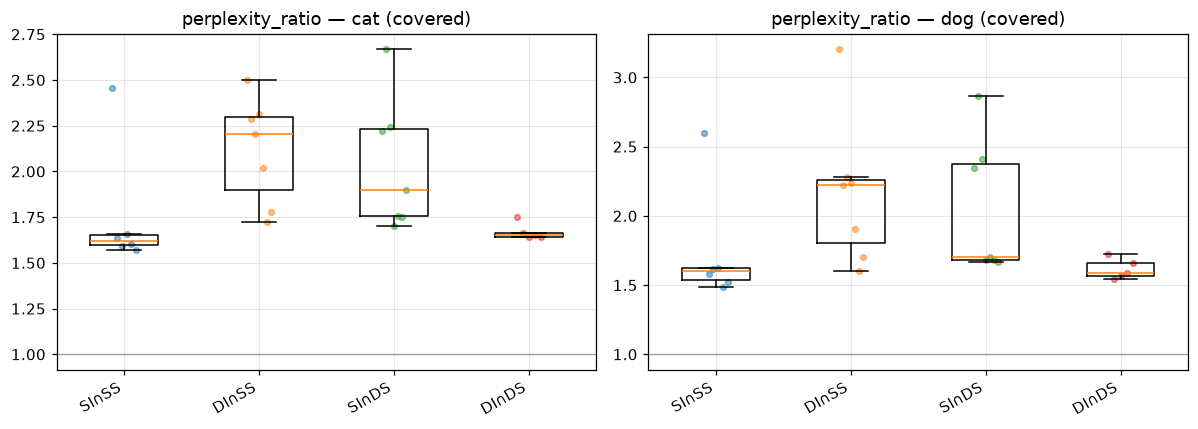

In [18]:
fc_t = fc[~fc["is_control"]].copy()
fc_target = annotate_pairing(fc_t[fc_t["is_target"]].copy())
print("FC coverage: treat configs",
      fc_t.drop_duplicates(["animal", "model", "teacher_tag"]).shape[0],
      "/ pref treat",
      pref[~pref.is_control].drop_duplicates(["animal", "model", "teacher_tag"]).shape[0],
      "; FC all configs (treat+ctrl)",
      fc.drop_duplicates(["animal", "model", "teacher_tag", "is_control"]).shape[0])

print("FC target_share_mean by corner (covered configs only):")
display(
    fc_target.groupby(["animal", "corner"])["target_share_mean"]
    .agg(["mean", "std", "count"])
    .reset_index()
)

# Representative config for the full candidate-share vector: prefer a covered
# same-init pairing, else fall back to the first covered config.
rep = fc_t.copy()
rep_same = fc_target[fc_target["corner"] == CORNER_SHARED_INIT_SHARED_STREAM]
rep_pool = rep_same if len(rep_same) else fc_t
rep_key = rep_pool.drop_duplicates(["animal", "model", "teacher_tag"]).iloc[0]
vec = rep[
    (rep.animal == rep_key.animal)
    & (rep.model == rep_key.model)
    & (rep.teacher_tag == rep_key.teacher_tag)
][["candidate", "is_target", "candidate_share"]].sort_values("candidate_share", ascending=False)
print("Representative candidate-share vector:",
      rep_key.animal, short_model(rep_key.model), rep_key.teacher_tag)
display(vec)

cap_t = annotate_pairing(cap[~cap["is_control"]].copy())
print("Capability columns:", [c for c in cap.columns if "ppl" in c or "bench" in c or "perplex" in c])
assert not any(c.startswith("bench_") for c in cap.columns)
print("perplexity_ratio by corner:")
display(
    cap_t.groupby(["animal", "corner"])["perplexity_ratio"]
    .agg(["mean", "std", "count"])
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, animal in zip(axes, ("cat", "dog")):
    sub = cap_t[cap_t.animal == animal]
    if sub.empty:
        ax.set_title(f"{animal}: no cap rows")
        continue
    aplots.strip_box(
        ax,
        groups_for_strip(sub, "corner", "perplexity_ratio", CORNER_ORDER),
        [CORNER_SHORT[c].split("\n")[0] for c in CORNER_ORDER],
    )
    ax.axhline(1.0, color="0.6", lw=0.8)
    ax.set_title(f"perplexity_ratio — {animal} (covered)")
    ax.tick_params(axis="x", labelrotation=30)
plt.tight_layout()
plt.show()


## 13. Probe trajectories by corner + divergence QC


Diverged leaves at frozen tag: 1


,animal,model,teacher_tag,gseed,p_target,ppl,run_dir
123,cat,pythia-160m,sdf-ep5_lr5e-5_r128a128-tfs0_tbase-data-seed1,0,0.16987,131.244049,/mnt/ssd-2/soar-subliminal/vishesh/subliminal_...


Diverged leaf trajectory (transient spike expected):


,step,ppl,p_target
36,50,91.457062,0.012169
37,100,105.461571,0.032003
38,150,108.046928,0.042662
39,200,1079.677734,0.005460
40,250,372.978821,0.020254
41,300,165.881042,0.062213
42,350,184.439041,0.048829
43,400,149.731033,0.117581
44,450,136.318008,0.141365
45,500,134.222702,0.129813


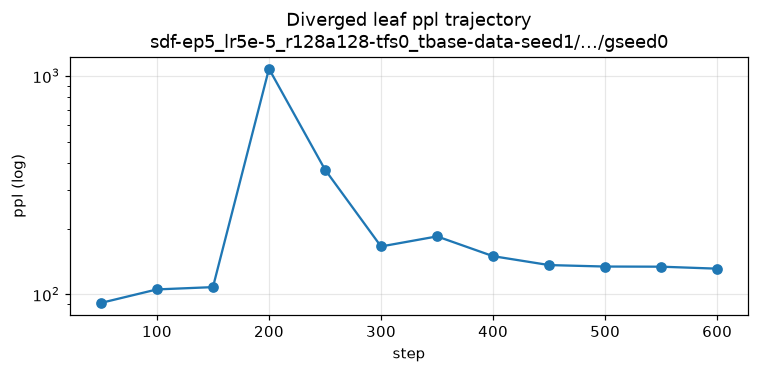

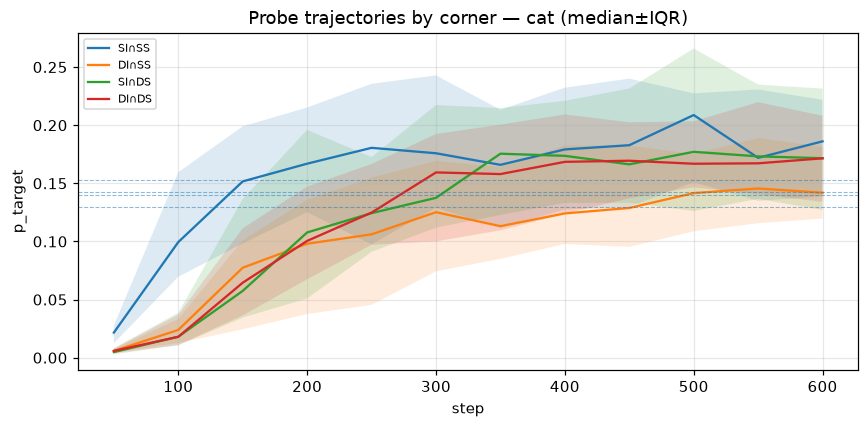

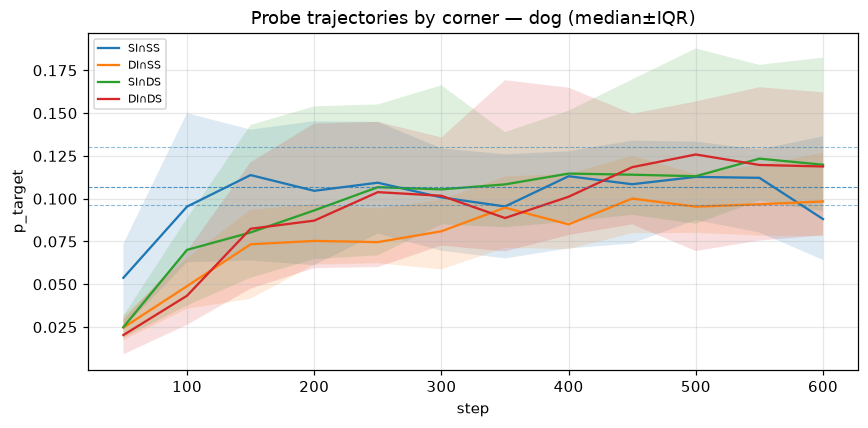

End-of-run vs peak p_target by corner:


p_target    p_peak
animal corner                                       
cat    diff_init_diff_stream      0.172010  0.215201
       diff_init_shared_stream    0.150741  0.166419
       shared_init_diff_stream    0.180766  0.229117
       shared_init_shared_stream  0.182600  0.235188
dog    diff_init_diff_stream      0.123435  0.154818
       diff_init_shared_stream    0.103160  0.123535
       shared_init_diff_stream    0.137554  0.162736
       shared_init_shared_stream  0.107700  0.151938

Sensitivity of corner means to diverged leaf:


which                                  all  excl_diverged      diff
animal corner                                                      
cat    diff_init_diff_stream      0.289416       0.289416  0.000000
       diff_init_shared_stream    0.202851       0.202851  0.000000
       shared_init_diff_stream    0.229105       0.230719 -0.001614
       shared_init_shared_stream  0.253539       0.253539  0.000000
dog    diff_init_diff_stream      0.137878       0.137878  0.000000
       diff_init_shared_stream    0.109067       0.109067  0.000000
       shared_init_diff_stream    0.128041       0.128041  0.000000
       shared_init_shared_stream  0.109882       0.109882  0.000000

Max |diff|: 0.0016138768755922794


In [19]:
eor = end_of_run_probes(probes)
peak = peak_probes(probes)
eor_t = annotate_pairing(eor[~eor.is_control].copy())
peak_t = annotate_pairing(peak[~peak.is_control].copy())

div_leaves = eor[eor["diverged"]]
print(f"Diverged leaves at frozen tag: {len(div_leaves)}")
display(div_leaves[["animal", "model", "teacher_tag", "gseed", "p_target", "ppl", "run_dir"]])

if len(div_leaves):
    rd = div_leaves.iloc[0]["run_dir"]
    traj = probes[probes["run_dir"] == rd][["step", "ppl", "p_target"]].sort_values("step")
    print("Diverged leaf trajectory (transient spike expected):")
    display(traj)
    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.plot(traj["step"], traj["ppl"], marker="o")
    ax.set_yscale("log")
    ax.set_xlabel("step")
    ax.set_ylabel("ppl (log)")
    ax.set_title(f"Diverged leaf ppl trajectory\n{Path(rd).parent.parent.name}/.../{Path(rd).name}")
    plt.tight_layout()
    plt.show()

# Median ± IQR bands by corner.
for animal in ("cat", "dog"):
    sub = annotate_pairing(probes[(~probes.is_control) & (probes.animal == animal)].copy())
    fig, ax = plt.subplots(figsize=(8, 4))
    for corner in CORNER_ORDER:
        g = sub[sub.corner == corner]
        if g.empty:
            continue
        band = g.groupby("step")["p_target"].agg(
            med="median",
            q1=lambda s: s.quantile(0.25),
            q3=lambda s: s.quantile(0.75),
        )
        ax.plot(band.index, band["med"], label=CORNER_SHORT[corner].split("\n")[0])
        ax.fill_between(band.index, band["q1"], band["q3"], alpha=0.15)
    # teacher reference: mean teacher_p_target per corner
    tp_ref = eor_t[eor_t.animal == animal].groupby("corner")["teacher_p_target"].mean()
    for corner, val in tp_ref.items():
        ax.axhline(val, ls="--", lw=0.7, alpha=0.5)
    ax.set_xlabel("step")
    ax.set_ylabel("p_target")
    ax.set_title(f"Probe trajectories by corner — {animal} (median±IQR)")
    ax.legend(fontsize=7)
    plt.tight_layout()
    plt.show()

print("End-of-run vs peak p_target by corner:")
cmp = eor_t.merge(
    peak_t[["animal", "model", "teacher_tag", "gseed", "p_target"]].rename(columns={"p_target": "p_peak"}),
    on=["animal", "model", "teacher_tag", "gseed"],
    how="left",
)
display(cmp.groupby(["animal", "corner"])[["p_target", "p_peak"]].mean())

# Sensitivity: §5 corner means with/without diverged leaf (leaf-level deltas).
leaf_d2 = leaf_d.copy()
if len(div_leaves):
    excl = leaf_d2[leaf_d2.run_dir != div_leaves.iloc[0].run_dir]
else:
    excl = leaf_d2
sens = []
for animal in ("cat", "dog"):
    for label, frame in (("all", leaf_d2), ("excl_diverged", excl)):
        for corner in CORNER_ORDER:
            mu = frame[(frame.animal == animal) & (frame.corner == corner)]["subliminal_delta"].mean()
            sens.append({"animal": animal, "which": label, "corner": corner, "mean_delta": mu})
sens_df = pd.DataFrame(sens)
sens_wide = sens_df.pivot_table(index=["animal", "corner"], columns="which", values="mean_delta")
sens_wide["diff"] = sens_wide["all"] - sens_wide["excl_diverged"]
print("Sensitivity of corner means to diverged leaf:")
display(sens_wide)
print("Max |diff|:", float(sens_wide["diff"].abs().max()))


## 14. Optimization / loss-matching check


n_train_steps unique: [625]
n_train_prompts unique: [20000]
final_train_loss null count: 0 / 282
optimizer_class unique: [None]
final_train_loss by corner:


mean       std  count
animal corner                                              
cat    diff_init_diff_stream      0.872685  0.192680     30
       diff_init_shared_stream    0.985694  0.276835     39
       shared_init_diff_stream    0.897266  0.219282     39
       shared_init_shared_stream  0.568922  0.395702     33
dog    diff_init_diff_stream      0.843187  0.188887     30
       diff_init_shared_stream    0.987697  0.302270     39
       shared_init_diff_stream    0.887194  0.241511     39
       shared_init_shared_stream  0.542756  0.409844     33

End-step trainer metrics by corner:
loss


animal,cat,dog
corner,,
diff_init_diff_stream,0.806347,0.781010
diff_init_shared_stream,0.903210,0.913831
shared_init_diff_stream,0.815795,0.817249
shared_init_shared_stream,0.487552,0.474573


grad_norm


animal,cat,dog
corner,,
diff_init_diff_stream,6.358603,4.417527
diff_init_shared_stream,7.437814,11.149685
shared_init_diff_stream,7.434424,8.194248
shared_init_shared_stream,5.137390,5.714860


... (4 outputs left out)

student_entropy


animal,cat,dog
corner,,
diff_init_diff_stream,2.660897,2.694575
diff_init_shared_stream,2.607476,2.662584
shared_init_diff_stream,2.647050,2.717494
shared_init_shared_stream,2.616406,2.671861


distinct_2


animal,cat,dog
corner,,
diff_init_diff_stream,0.818392,0.819475
diff_init_shared_stream,0.807884,0.807461
shared_init_diff_stream,0.819390,0.821223
shared_init_shared_stream,0.836792,0.837065


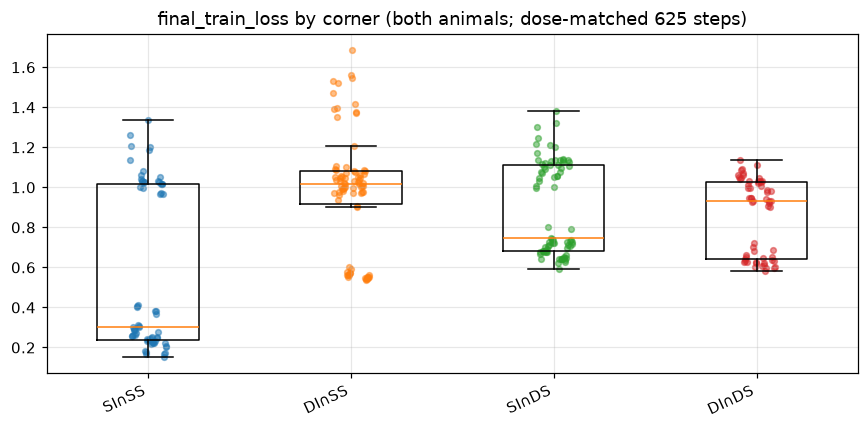

In [20]:
man_t = annotate_pairing(manifests[~manifests.is_control].copy())
print("n_train_steps unique:", sorted(man_t.n_train_steps.dropna().unique().tolist()))
print("n_train_prompts unique:", sorted(man_t.n_train_prompts.dropna().unique().tolist()))
print("final_train_loss null count:", int(man_t.final_train_loss.isna().sum()), "/", len(man_t))
print("optimizer_class unique:", man_t.optimizer_class.unique().tolist())
assert set(man_t.n_train_steps.unique()) == {625}
assert set(man_t.n_train_prompts.unique()) == {20000}

print("final_train_loss by corner:")
display(man_t.groupby(["animal", "corner"])["final_train_loss"].agg(["mean", "std", "count"]))

# Trainer-log end-of-run metrics.
logs_t = annotate_pairing(logs[~logs.is_control].copy())
last = logs_t.sort_values("step").groupby(
    ["animal", "model", "teacher_tag", "gseed"], as_index=False
).tail(1)
print("End-step trainer metrics by corner:")
for col in ("loss", "grad_norm", "fwd_kl", "rev_kl", "student_entropy", "distinct_2"):
    print(col)
    display(last.groupby(["animal", "corner"])[col].mean().unstack(0))

fig, ax = plt.subplots(figsize=(8, 4))
aplots.strip_box(
    ax,
    groups_for_strip(man_t, "corner", "final_train_loss", CORNER_ORDER),
    [CORNER_SHORT[c].split("\n")[0] for c in CORNER_ORDER],
)
ax.set_title("final_train_loss by corner (both animals; dose-matched 625 steps)")
ax.tick_params(axis="x", labelrotation=25)
plt.tight_layout()
plt.show()


## 15. Behavioural leakage telemetry

`flagged_rate` / `mention_rate` / `matched_form_counts` are **supporting
telemetry**, not trait metrics. Treatments mention the animal far more than
controls by construction of biased teachers; correlation with
`subliminal_delta` is exploratory.


flagged_rate treat mean: 0.17904343971631206 ctrl mean: 0.007069047619047619


mean       std  count
animal corner                                              
cat    diff_init_diff_stream      0.174542  0.049669     30
       diff_init_shared_stream    0.144205  0.058407     39
       shared_init_diff_stream    0.158224  0.055672     39
       shared_init_shared_stream  0.227502  0.046295     33
dog    diff_init_diff_stream      0.172175  0.021164     30
       diff_init_shared_stream    0.164571  0.051236     39
       shared_init_diff_stream    0.183964  0.047324     39
       shared_init_shared_stream  0.217988  0.029634     33

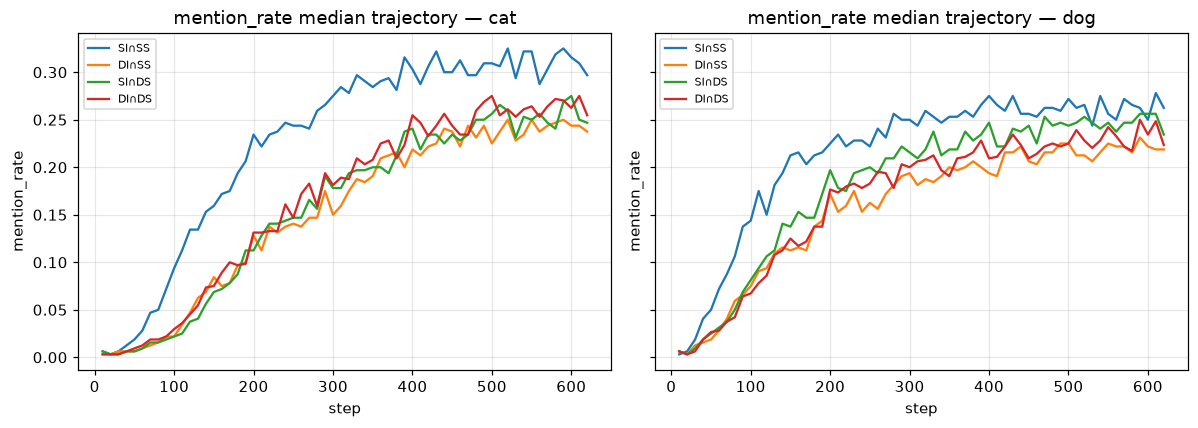

Top matched forms (all treatments): [('dogs', 272966), ('cat', 221359), ('cats', 203928), ('dog', 190915), ('pet', 66467), ('feline', 30954), ('canine', 9068), ('puppy', 4986), ('fetch', 3252), ('bark', 1659), ('paw', 1395), ('kitten', 975)]
cat: Spearman(flagged_rate, delta) ρ=0.467 p=0.00809 n=31
dog: Spearman(flagged_rate, delta) ρ=0.050 p=0.788 n=31


In [21]:
roll_t = annotate_pairing(rollouts[~rollouts.is_control].copy())
roll_c = rollouts[rollouts.is_control]
print("flagged_rate treat mean:", float(roll_t.flagged_rate.mean()),
      "ctrl mean:", float(roll_c.flagged_rate.mean()))
display(roll_t.groupby(["animal", "corner"])["flagged_rate"].agg(["mean", "std", "count"]))

# mention_rate trajectory from trainer logs
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, animal in zip(axes, ("cat", "dog")):
    sub = logs_t[logs_t.animal == animal]
    for corner in CORNER_ORDER:
        g = sub[sub.corner == corner].groupby("step")["mention_rate"].median()
        ax.plot(g.index, g.values, label=CORNER_SHORT[corner].split("\n")[0])
    ax.set_title(f"mention_rate median trajectory — {animal}")
    ax.set_xlabel("step")
    ax.set_ylabel("mention_rate")
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

# Form composition for treatments (aggregate counts).
ctr = Counter()
for d in roll_t["matched_form_counts"]:
    if isinstance(d, dict):
        ctr.update(d)
print("Top matched forms (all treatments):", ctr.most_common(12))

# Correlate flagged_rate with pairing-level delta.
roll_pair = (
    roll_t.groupby(["animal", "student_base", "teacher_base", "corner"], dropna=False)["flagged_rate"]
    .mean()
    .reset_index()
)
merged = pd_delta.merge(
    roll_pair,
    on=["animal", "student_base", "teacher_base", "corner"],
    how="left",
)
for animal in ("cat", "dog"):
    s = merged[merged.animal == animal].dropna(subset=["flagged_rate"])
    rho = spearmanr(s["flagged_rate"], s["subliminal_delta"])
    print(f"{animal}: Spearman(flagged_rate, delta) ρ={rho.statistic:.3f} p={rho.pvalue:.3g} n={len(s)}")


## 16. Independent legacy replication (`cats_wide_run`)

Older cat-only tree at a **different** teacher tag (`sdf-ep3_lr5e-5_r64a64`) and
different student recipe. Only a **sign / qualitative** comparison is valid.
Check on-disk coverage before claiming anything.


In [22]:
LEGACY_SUB = "gkd_students/cats_wide_run"
LEGACY = OUTPUT_ROOT / LEGACY_SUB
print("legacy tree exists:", LEGACY.exists())
if LEGACY.exists():
    leg_pref = load_gkd_preference_results(OUTPUT_ROOT, LEGACY_SUB)
    leg_man = load_gkd_train_manifests(OUTPUT_ROOT, LEGACY_SUB)
    print("legacy preference rows:", len(leg_pref), "manifests:", len(leg_man))
    print("legacy animals:", sorted(leg_pref.animal.unique().tolist()))
    print("legacy gkd_tag top:", leg_pref.gkd_tag.value_counts().head(8).to_dict())
    print("legacy teacher_tag top:", leg_pref.teacher_tag.value_counts().head(8).to_dict())
    # Same-init vs any cross (_tbase-) on overlapping tags if present.
    leg_delta = subliminal_delta(leg_pref)
    if len(leg_delta):
        leg_delta = leg_delta[leg_delta["set"] == "test"].copy()
        leg_delta["is_cross"] = leg_delta["teacher_cross_init"].astype(bool)
        print("legacy test delta rows:", len(leg_delta))
        display(
            leg_delta.groupby(["is_cross"])["subliminal_delta"]
            .agg(["mean", "std", "count"])
            .reset_index()
        )
        # Cross specifically to weight-seed1 if present.
        cross_w1 = leg_delta[leg_delta["teacher_base_label"] == "weight-seed1"]
        same = leg_delta[~leg_delta["teacher_cross_init"].astype(bool)]
        print("legacy same-init mean delta:", float(same.subliminal_delta.mean()) if len(same) else None,
              "n=", len(same))
        print("legacy tbase-weight-seed1 mean delta:",
              float(cross_w1.subliminal_delta.mean()) if len(cross_w1) else None,
              "n=", len(cross_w1))
        print(
            "Qualitative: cross-init transfer appears?" ,
            bool(len(cross_w1) and cross_w1.subliminal_delta.mean() > 0),
        )
    else:
        print("legacy subliminal_delta empty — coverage insufficient")
else:
    print("legacy tree missing; skip")


legacy tree exists: True
legacy preference rows: 1326 manifests: 341
legacy animals: ['cat']
legacy gkd_tag top: {'lmb1.0_b1.0_lora_lr2e-4_e5_r64a64': 507, 'lmb1.0_b0.0_lora_lr2e-4_e5_r64a64': 312, 'lmb1.0_b1.0_lora_lr2e-4_e5_r1a1': 273, 'lmb1.0_b1.0_lora_lr2e-4_e5_r128a128': 234}
legacy teacher_tag top: {'': 299, 'sdf-ep3_lr5e-5_r64a64-tfs0': 286, 'sdf-ep3_lr5e-5_r64a64-tfs1': 260, 'sdf-ep3_lr5e-5_r64a64-tfs2': 247, 'sdf-ep3_lr5e-5_r64a64-tfs0_tbase-weight-seed1': 13, 'sdf-ep3_lr5e-5_r64a64-tfs1_tbase-weight-seed1': 13, 'sdf-ep3_lr5e-5_r64a64-tfs2_tbase-weight-seed1': 13, 'sdf-ep3_lr5e-5_r64a64-tfs0_tbase-weight-seed2': 13}
legacy test delta rows: 28


,is_cross,mean,std,count
0,False,0.122557,0.044737,22
1,True,0.137074,0.047667,6


legacy same-init mean delta: 0.12255727188735116 n= 22
legacy tbase-weight-seed1 mean delta: 0.13149837284342442 n= 1
Qualitative: cross-init transfer appears? True


## 17. Verdict framing (computed)

Maps §5 / §7 / §8 onto `{init matters / batch composition matters / both /
neither}` and onto H1 vs H2 / Cloud shared-init requirement, using the thresholds
declared in §5. **Do not hardcode the conclusion — the cell computes it.**


In [23]:
# Student-base-controlled contrast: mean delta_minus_same for H1 cell vs compare cell.
sb_rows = []
for animal in ("cat", "dog"):
    s = paired_diff[paired_diff.animal == animal]
    a = s.loc[s.corner == H1_CELL, "delta_minus_same"]
    b = s.loc[s.corner == H1_COMPARE, "delta_minus_same"]
    if len(a) and len(b):
        obs = float(a.mean() - b.mean())
        rng = np.random.default_rng(BOOTSTRAP_SEED)
        boots = [
            float(rng.choice(a.values, size=len(a), replace=True).mean()
                  - rng.choice(b.values, size=len(b), replace=True).mean())
            for _ in range(2000)
        ]
        lo, hi = np.quantile(boots, [0.025, 0.975])
        sb_rows.append({
            "animal": animal, "contrast": obs, "ci_lo": float(lo), "ci_hi": float(hi),
            "verdict": verdict_from_contrast(obs, float(lo), float(hi)),
        })
h1_student_controlled = pd.DataFrame(sb_rows)
print("H1 after within-student-base control:")
display(h1_student_controlled)

def _label_factor(v_raw: str, v_resid: str, v_student: str) -> str:
    votes = [v_raw, v_resid, v_student]
    if votes.count("support_H1_shared_stream") >= 2:
        return "batch_composition_matters"
    if votes.count("support_reverse_shared_init") >= 2:
        return "init_matters"
    if votes.count("null_compatible_with_H2") >= 2:
        return "neither_H2_compatible"
    if "support_H1_shared_stream" in votes and "support_reverse_shared_init" in votes:
        return "both_unstable"
    return "inconclusive"


factor_labels = {}
for animal in ("cat", "dog"):
    v_raw = h1_summary.set_index("animal").loc[animal, "verdict"]
    v_res = h1_after_teacher.set_index("animal").loc[animal, "verdict"]
    v_stu = h1_student_controlled.set_index("animal").loc[animal, "verdict"]
    factor_labels[animal] = {
        "raw": v_raw,
        "teacher_resid": v_res,
        "student_controlled": v_stu,
        "factor_call": _label_factor(v_raw, v_res, v_stu),
    }

# Cloud shared-init requirement: same_init cell mean vs grand cross-init mean.
cloud_rows = []
for animal in ("cat", "dog"):
    d = pd_delta[pd_delta.animal == animal]
    same = d.loc[d.corner == CORNER_SHARED_INIT_SHARED_STREAM, "subliminal_delta"]
    cross = d.loc[d.corner != CORNER_SHARED_INIT_SHARED_STREAM, "subliminal_delta"]
    cloud_rows.append({
        "animal": animal,
        "same_init_mean": float(same.mean()),
        "cross_init_mean": float(cross.mean()),
        "same_minus_cross": float(same.mean() - cross.mean()),
        "cross_positive_frac": float((cross > 0).mean()),
    })
cloud_df = pd.DataFrame(cloud_rows)

computed_verdict = {
    "h1_raw": h1_summary.set_index("animal")[
        ["contrast", "ci_lo", "ci_hi", "verdict"]
    ].to_dict("index"),
    "h1_resid_teacher": h1_after_teacher.set_index("animal")[
        ["contrast_resid", "ci_lo", "ci_hi", "verdict"]
    ].to_dict("index"),
    "per_animal_factor": factor_labels,
    "cloud_shared_init_check": cloud_df.to_dict(orient="records"),
    "h1_vs_h2": {
        a: (
            "H1" if factor_labels[a]["factor_call"] == "batch_composition_matters"
            else "H2_compatible" if factor_labels[a]["factor_call"] == "neither_H2_compatible"
            else "init_over_batch" if factor_labels[a]["factor_call"] == "init_matters"
            else "unresolved"
        )
        for a in ("cat", "dog")
    },
}
print("COMPUTED VERDICT")
print(json.dumps(computed_verdict, indent=2, default=str))
display(cloud_df)


H1 after within-student-base control:


,animal,contrast,ci_lo,ci_hi,verdict
0,cat,-0.013958,-0.067442,0.039089,inconclusive
1,dog,-0.012012,-0.052993,0.026844,inconclusive


COMPUTED VERDICT
{
  "h1_raw": {
    "cat": {
      "contrast": -0.025006478081707445,
      "ci_lo": -0.06587501734968775,
      "ci_hi": 0.01468213417887497,
      "verdict": "inconclusive"
    },
    "dog": {
      "contrast": -0.020705728903488263,
      "ci_lo": -0.05211441126188741,
      "ci_hi": 0.010282220178827985,
      "verdict": "inconclusive"
    }
  },
  "h1_resid_teacher": {
    "cat": {
      "contrast_resid": -0.016020563339219595,
      "ci_lo": -0.05126322217058925,
      "ci_hi": 0.015832850909414248,
      "verdict": "inconclusive"
    },
    "dog": {
      "contrast_resid": -0.023492247017343974,
      "ci_lo": -0.05320415662554287,
      "ci_hi": 0.007040313291400076,
      "verdict": "inconclusive"
    }
  },
  "per_animal_factor": {
    "cat": {
      "raw": "inconclusive",
      "teacher_resid": "inconclusive",
      "student_controlled": "inconclusive",
      "factor_call": "inconclusive"
    },
    "dog": {
      "raw": "inconclusive",
      "teacher_resid"

,animal,same_init_mean,cross_init_mean,same_minus_cross,cross_positive_frac
0,cat,0.223574,0.226895,-0.003321,1.0
1,dog,0.096290,0.121126,-0.024836,1.0


## 18. Takeaways checklist

Computed bullets below are rebuilt from the frames in this run (re-run the
notebook before quoting). The following markdown cell is the prose synthesis of
the **executed** outputs — what claims this Stage B notebook can and cannot make.


In [24]:
takeaways = [
    {
        "id": "T1",
        "section": "2",
        "grade": "inventory",
        "claim": (
            f"Stage B frozen tag {FROZEN} has "
            f"{int((~manifests.is_control).sum())} treatments + "
            f"{int(manifests.is_control.sum())} controls across "
            f"{len(stage_b_pairs())} pairings; corner counts "
            f"{CORNER_COUNTS_EXPECTED}."
        ),
    },
    {
        "id": "T2",
        "section": "0",
        "grade": "premise",
        "claim": (
            f"init_equality verdict={init_eq.get('verdict')!r} — premise guard for shared-init labels."
        ),
    },
    {
        "id": "T3",
        "section": "5",
        "grade": "pre-specified",
        "claim": (
            "H1 contrast (DI∩SS − SI∩DS) per animal: "
            + "; ".join(
                f"{r.animal}={r.contrast:.3f} CI[{r.ci_lo:.3f},{r.ci_hi:.3f}]→{r.verdict}"
                for r in h1_summary.itertuples()
            )
        ),
    },
    {
        "id": "T4",
        "section": "7",
        "grade": "confound",
        "claim": (
            "After residualising on teacher_p_target: "
            + "; ".join(
                f"{r.animal}={r.contrast_resid:.3f}→{r.verdict}"
                for r in h1_after_teacher.itertuples()
            )
        ),
    },
    {
        "id": "T5",
        "section": "8",
        "grade": "confound",
        "claim": (
            "After within-student-base control: "
            + "; ".join(
                f"{r.animal}={r.contrast:.3f}→{r.verdict}"
                for r in h1_student_controlled.itertuples()
            )
        ),
    },
    {
        "id": "T6",
        "section": "17",
        "grade": "verdict",
        "claim": (
            "Factor calls: "
            + "; ".join(f"{a}={factor_labels[a]['factor_call']}" for a in ("cat", "dog"))
            + " | H1 vs H2: "
            + "; ".join(f"{a}={computed_verdict['h1_vs_h2'][a]}" for a in ("cat", "dog"))
        ),
    },
    {
        "id": "T7",
        "section": "6",
        "grade": "exploratory",
        "claim": (
            "seed0 vs cyclic replication diffs: "
            + "; ".join(
                f"{r.animal} {r.seed0_group}−{r.cyclic_group}={r.diff_seed0_minus_cyclic:.3f}"
                for r in repl.itertuples()
            )
        ),
    },
    {
        "id": "T8",
        "section": "13",
        "grade": "QC",
        "claim": (
            f"Diverged leaves={len(div_leaves)}; max |corner-mean shift| when excluded="
            f"{float(sens_wide['diff'].abs().max()):.5f}."
        ),
    },
    {
        "id": "T9",
        "section": "12",
        "grade": "guardrail",
        "claim": (
            f"FC treat configs="
            f"{fc_t.drop_duplicates(['animal','model','teacher_tag']).shape[0]}/"
            f"{pref[~pref.is_control].drop_duplicates(['animal','model','teacher_tag']).shape[0]}; "
            f"no bench_* columns; perplexity_ratio is the capability guardrail."
        ),
    },
    {
        "id": "T10",
        "section": "16",
        "grade": "replication",
        "claim": (
            "Legacy cats_wide_run qualitative cross-init check ran "
            f"(tree_exists={LEGACY.exists()})."
        ),
    },
]

print("TAKEAWAYS")
for t in takeaways:
    print(f"[{t['id']} §{t['section']} | {t['grade']}] {t['claim']}")

print("\nTHIS NOTEBOOK DOES NOT ESTABLISH")
does_not = [
    "No E2 predictor correlations (E3 CKA / E4 coverage / E5 EAS) — interp/{run_set_id}/ absent; any such Spearman would be post-hoc.",
    "No mechanism claim (steering / SAE / causal patch).",
    "No other student recipes / β / λ / optimizer / full-FT — frozen LoRA headline only.",
    "Only pythia-160m family; only cat+dog; only LoRA students.",
    "seed-0 arms rest on step-0 equality verified for data-seed1 (and the recorded init_equality pairs) — not a universal guarantee for every seed.",
    "Angela's template+numbers tree is not compared (different workflow/schema, teammate directory, seed-0-teacher arms only).",
    "E2 formal prereg file was not on disk at analysis time; design/hypotheses are taken from the plan doc.",
]
for i, line in enumerate(does_not, 1):
    print(f"  {i}. {line}")


TAKEAWAYS
[T1 §2 | inventory] Stage B frozen tag lmb1.0_b1.0_lora_lr4e-4_e1_r8a16 has 282 treatments + 42 controls across 31 pairings; corner counts {'shared_init_shared_stream': 7, 'diff_init_shared_stream': 9, 'shared_init_diff_stream': 9, 'diff_init_diff_stream': 6}.
[T2 §0 | premise] init_equality verdict='as_expected' — premise guard for shared-init labels.
[T3 §5 | pre-specified] H1 contrast (DI∩SS − SI∩DS) per animal: cat=-0.025 CI[-0.066,0.015]→inconclusive; dog=-0.021 CI[-0.052,0.010]→inconclusive
[T4 §7 | confound] After residualising on teacher_p_target: cat=-0.016→inconclusive; dog=-0.023→inconclusive
[T5 §8 | confound] After within-student-base control: cat=-0.014→inconclusive; dog=-0.012→inconclusive
[T6 §17 | verdict] Factor calls: cat=inconclusive; dog=inconclusive | H1 vs H2: cat=unresolved; dog=unresolved
[T7 §6 | exploratory] seed0 vs cyclic replication diffs: cat seed0_data−data_cyclic=-0.014; cat seed0_weight−weight_cyclic=-0.014; dog seed0_data−data_cyclic=0.003; 

## Final takeaway — what this notebook establishes

This cell is a prose summary of the **executed** outputs above (inventory,
heatmaps, 2×2 bootstrap tables, confound controls, seed ANOVA, prompt-set sign
tests, FC/capability, probe QC, loss, leakage, legacy check, verdict JSON).
Numbers are taken from those cells; nothing below is assumed beyond what the
notebook already computed. The §18 checklist code reprints the same quantities
from live frames.

### Scope and evidence grade

- Campaign `20260727_slbreadth_160m` finished with `CAMPAIGN_DONE=True`
  (`finalize` at `2026-07-31T14:59:28Z`). Teachers:
  `sdf_teachers/20260726_crossinit_160m`. Stage B analyses the **frozen
  headline** student tag derived from `freeze_report.json`:
  **`lmb1.0_b1.0_lora_lr4e-4_e1_r8a16`** (β=1, r=8, α=16, lr=4e-4, e=1).
- Design fill: **31** pairings / **282** treatment leaves / **42** controls;
  corners **SI∩SS=7**, **DI∩SS=9**, **SI∩DS=9**, **DI∩DS=6**. Preference
  summaries cover all **94** treat configs; FC/capability cover **50/94**
  (headline-arm subset). No `bench_*` columns — capability is
  `perplexity_ratio` only.
- **`init_equality` verdict `as_expected`** (original≈data-seed1 at 0/148
  mismatch; weight differs 50/148 as expected) — licenses shared-init /
  shared-stream labels for this tree.
- **E2 formal prereg file:** absent on disk (only `PREREG_OPTPARAM.md`);
  `interp/{run_set_id}/` absent. The 2×2 / H1 contrast is treated as
  **pre-specified by the plan doc**; everything beyond that is exploratory.
  No E3/E4/E5 predictor correlations are attempted.
- Tree is a **real SSD-2 directory** (hot) in this executed run
  (`tree.is_symlink()=False`).

### What Stage B shows

1. **Control floors stay low; dog ≃ 2× cat.** Eval-grade test control
   `p_target` means: cat **0.0045**, dog **0.0088** (ratio **1.97**). All
   SL comparisons stay **within-animal**.

2. **Subliminal transfer is robust across the whole 2×2.** On the primary
   eval-grade metric (`subliminal_delta` on `test`), pairing-cluster corner
   means are all clearly positive:
   - cat: SI∩SS **0.224**, DI∩SS **0.203**, SI∩DS **0.228**, DI∩DS **0.260**
   - dog: SI∩SS **0.096**, DI∩SS **0.111**, SI∩DS **0.131**, DI∩DS **0.121**
   Prompt-set sign tests: **62/62** positive Δ on every set
   (consensus/dislike/favorite/register/test/validation; *p* ≈ **2×10⁻¹⁹**
   each), and **frac_positive = 1.0** in every set × corner cell. Cloud-style
   “shared init required” is **not** supported here: pooled cross-init mean ≥
   same-init (cat same−cross **−0.003**; dog **−0.025**) with
   **`cross_positive_frac = 1.0`** for both animals.

3. **Pre-specified H1 (DI∩SS − SI∩DS) is inconclusive for both animals.**
   Under the declared decision rule (support H1 iff CI entirely above
   `+0.01`):
   - cat: **−0.025** CI **[−0.066, 0.015]** → **inconclusive**
     (`p_boot_h1_greater ≈ 0.90`; compare cell mean **0.228** > H1 cell
     **0.203**)
   - dog: **−0.021** CI **[−0.052, 0.010]** → **inconclusive**
     (`p_boot ≈ 0.90`; compare **0.131** > H1 **0.111**)
   Point estimates favor the *shared-init / different-stream* cell, not H1 —
   but CIs cover 0 and do not clear the ±0.01 threshold. Main effects of
   shared-stream and shared-init are likewise CI-overlapping-zero.

4. **Confound controls do not flip the H1 call.** After residualising on
   pairing-level `teacher_p_target`: cat **−0.016**, dog **−0.023**
   (still inconclusive). After within-student-base control
   (`delta_minus_same`): cat **−0.014**, dog **−0.012** (still
   inconclusive). Factor call and `h1_vs_h2` remain **`inconclusive` /
   `unresolved`** for both animals — a null with these CIs cannot cleanly
   select H1 vs H2.

5. **Teacher strength varies by init (a real confound to watch), but
   transfer efficiency stays high.** Mean `teacher_p_target` spans ~0.10–0.20
   (cat) and ~0.08–0.18 (dog) across teacher bases; controls sit near the
   floor (~0.003 / ~0.009). Corner mean transfer ratios (Δ / teacher) are
   typically **≳ 1** (cat ~1.5–2.0; dog ~0.9–1.2).

6. **Student-base and direction effects are secondary.** Within-student
   paired (cross − same_init) means are small relative to absolute Δ
   (cat DI∩SS **−0.017**, SI∩DS **−0.003**, DI∩DS **+0.038**; dog all
   slightly positive). Bidirectional edges (n=9/animal): cat mean asym
   **−0.005**, `sign_p=0.25`; dog **+0.025**, `sign_p=0.090` — not a
   decisive directionality claim. `seed0_*` vs cyclic replication diffs are
   within ~0.01–0.014 (exploratory small-n check).

7. **Pairing dominates seed noise.** On the 8 headline pairings × 9 leaves
   (144 leaves/animal): sequential SS fractions ≈ pairing **67–69%**,
   student-gseed **19–22%**, teacher-ftseed **10–12%** (residual
   structurally 0 at leaf identity). Corner rank stability over 1000 leaf
   bootstraps: dog **0.954**, cat **0.661**.

8. **Specificity is high where FC exists; capability is PPL-only.** On the
   50/94 covered treat configs, FC `target_share_mean` by corner is ~**0.84–0.88**
   (cat) and ~**0.79–0.86** (dog). Representative same-init vector puts mass
   on the target (cat **0.883** vs next animal **0.057**).
   `perplexity_ratio` by corner ~**1.6–2.2** (DI∩SS / SI∩DS higher than
   SI∩SS / DI∩DS) — guardrail only, no `bench_*`.

9. **QC / optimization / leakage do not overturn the transfer claim.**
   - Diverged leaves at frozen tag: **1** (transient ppl spike to ~1080 at
     step 200, recovered); excluding it shifts corner means by at most
     **0.0016**.
   - Dose is matched by construction: all leaves **625** steps / **20k**
     prompts; `final_train_loss` non-null on **282/282**. Same-init shared-stream
     ends at lower loss (~**0.54–0.57**) than cross corners (~**0.84–0.99**) —
     step budget matched, loss not equalized.
   - Behavioural `flagged_rate`: treat mean **0.179** vs ctrl **0.007**. Cat
     Spearman(flagged, Δ) **ρ=0.47**, *p*=**0.008**; dog **ρ=0.05**,
     *p*=**0.79**. Leakage is telemetry, not the trait metric.

10. **Independent legacy `cats_wide_run` (cat-only, different recipe) is
    qualitatively consistent.** Legacy test Δ: same-init mean **0.123**
    (n=22) vs cross **0.137** (n=6); notebook flag
    `cross-init transfer appears? True`. Different teacher/student HP
    (`ep3_lr5e-5_r64a64`, longer e5 LoRA) — replication of *direction*, not
    a pooled estimate.

### Bottom line — claims we can make

On PolyPythia-160M under this frozen on-policy GKD headline recipe, **Stage B
establishes that subliminal preference transfer is real across the confirmed
init × stream 2×2**, including different-init cells, with **100% positive**
eval-grade deltas on every prompt set × corner examined. Shared
initialization is **not** required for transfer in this tree. The
pre-specified **H1 batch-composition predictor** (DI∩SS beating SI∩DS) is
**not established** — contrasts are negative-pointing and CI-inconclusive
after teacher-strength and student-base controls — so **H1 vs H2 remains
unresolved** at this sample size (9 vs 9 pairings). Pairing identity explains
most leaf variance; seed noise is secondary but non-negligible.

### This notebook does not establish

1. E2 predictor correlations (E3 CKA / E4 coverage / E5 EAS) — no `interp/` tree.
2. Any mechanism claim (steering / SAE / causal patch).
3. Other student recipes / β / λ / optimizer / full-FT — frozen LoRA headline only.
4. Scope beyond pythia-160m, cat+dog, LoRA students.
5. Universal step-0 equality for every seed (only recorded `init_equality` pairs).
6. Angela’s template+numbers tree comparison (different workflow / directory).
7. A confirmatory E2 prereg filing — design taken from the plan doc; no E2 file on disk.
